# Projeto Airbnb Rio - Ferramenta de Previsão de Preço de Imóvel para pessoas comuns 

### Contexto

No Airbnb, qualquer pessoa que tenha um quarto ou um imóvel de qualquer tipo (apartamento, casa, chalé, pousada, etc.) pode ofertar o seu imóvel para ser alugado por diária.

Você cria o seu perfil de host (pessoa que disponibiliza um imóvel para aluguel por diária) e cria o anúncio do seu imóvel.

Nesse anúncio, o host deve descrever as características do imóvel da forma mais completa possível, de forma a ajudar os locadores/viajantes a escolherem o melhor imóvel para eles (e de forma a tornar o seu anúncio mais atrativo)

Existem dezenas de personalizações possíveis no seu anúncio, desde quantidade mínima de diária, preço, quantidade de quartos, até regras de cancelamento, taxa extra para hóspedes extras, exigência de verificação de identidade do locador, etc.

### Nosso objetivo

Construir um modelo de previsão de preço que permita uma pessoa comum que possui um imóvel possa saber quanto deve cobrar pela diária do seu imóvel.

Ou ainda, para o locador comum, dado o imóvel que ele está buscando, ajudar a saber se aquele imóvel está com preço atrativo (abaixo da média para imóveis com as mesmas características) ou não.

### O que temos disponível, inspirações e créditos

As bases de dados foram retiradas do site kaggle: https://www.kaggle.com/allanbruno/airbnb-rio-de-janeiro

Elas estão disponíveis para download abaixo da aula (se você puxar os dados direto do Kaggle pode ser que encontre resultados diferentes dos meus, afinal as bases de dados podem ter sido atualizadas).

Caso queira uma outra solução, podemos olhar como referência a solução do usuário Allan Bruno do kaggle no Notebook: https://www.kaggle.com/allanbruno/helping-regular-people-price-listings-on-airbnb

Você vai perceber semelhanças entre a solução que vamos desenvolver aqui e a dele, mas também algumas diferenças significativas no processo de construção do projeto.

- As bases de dados são os preços dos imóveis obtidos e suas respectivas características em cada mês.
- Os preços são dados em reais (R$)
- Temos bases de abril de 2018 a maio de 2020, com exceção de junho de 2018 que não possui base de dados

### Expectativas Iniciais

- Acredito que a sazonalidade pode ser um fator importante, visto que meses como dezembro costumam ser bem caros no RJ
- A localização do imóvel deve fazer muita diferença no preço, já que no Rio de Janeiro a localização pode mudar completamente as características do lugar (segurança, beleza natural, pontos turísticos)
- Adicionais/Comodidades podem ter um impacto significativo, visto que temos muitos prédios e casas antigos no Rio de Janeiro

Vamos descobrir o quanto esses fatores impactam e se temos outros fatores não tão intuitivos que são extremamente importantes.

### Importar Bibliotecas e Bases de Dados

In [1]:
import pandas as pd
import pathlib 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import train_test_split
import time

### Consolidar Base de Dados

In [2]:
meses = {
    'jan': 1,
    'fev': 2,
    'mar': 3,
    'abr': 4,
    'mai': 5,
    'jun': 6,
    'jul': 7,
    'ago': 8,
    'set': 9,
    'out': 10,
    'nov': 11,
    'dez': 12,
}

caminho_bases = pathlib.Path('dataset')

# Lista para guardar os DataFrames temporariamente
lista_dfs = []

for arquivo in caminho_bases.iterdir():
    # lê apenas os arquivos .csv da pasta
    if arquivo.suffix == '.csv':
        nome_mes = arquivo.name[:3]
        mes = meses[nome_mes]
        ano = arquivo.name[-8:]
        ano = int(ano.replace('.csv', ''))
        df = pd.read_csv(arquivo, low_memory=False)
        df['ano'] = ano
        df['mes'] = mes
        lista_dfs.append(df)

# Junta todos os DataFrames da lista em um único DataFrame
base_airbnb = pd.concat(lista_dfs, ignore_index=True)

display(base_airbnb)

,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,number_of_reviews_ltm,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms
0,14063,https://www.airbnb.com/rooms/14063,20180414160018,2018-04-14,Living in a Postcard,"Besides the most iconic's view, our apartment ...",NaN,"Besides the most iconic's view, our apartment ...",none,Best and favorite neighborhood of Rio. Perfect...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,17878,https://www.airbnb.com/rooms/17878,20180414160018,2018-04-14,Very Nice 2Br - Copacabana - WiFi,Please note that special rates apply for New Y...,- large balcony which looks out on pedestrian ...,Please note that special rates apply for New Y...,none,This is the best spot in Rio. Everything happe...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,24480,https://www.airbnb.com/rooms/24480,20180414160018,2018-04-14,Nice and cozy near Ipanema Beach,My studio is located in the best of Ipanema. ...,The studio is located at Vinicius de Moraes St...,My studio is located in the best of Ipanema. ...,none,"The beach, the lagoon, Ipanema is a great loca...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,25026,https://www.airbnb.com/rooms/25026,20180414160018,2018-04-14,Beautiful Modern Decorated Studio in Copa,"Our apartment is a little gem, everyone loves ...",This newly renovated studio (last renovations ...,"Our apartment is a little gem, everyone loves ...",none,Copacabana is a lively neighborhood and the ap...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,31560,https://www.airbnb.com/rooms/31560,20180414160018,2018-04-14,NICE & COZY 1BDR - IPANEMA BEACH,This nice and clean 1 bedroom apartment is loc...,This nice and clean 1 bedroom apartment is loc...,This nice and clean 1 bedroom apartment is loc...,none,Die Nachbarschaft von Ipanema ist super lebend...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
902205,38844730,https://www.airbnb.com/rooms/38844730,20190923212307,2019-09-24,TRANSAMERICA BARRA DA TIJUCA R IV,"Em estilo contemporâneo, o Transamerica Prime ...",NaN,"Em estilo contemporâneo, o Transamerica Prime ...",none,NaN,...,1.0,1.0,1125.0,1125.0,1.0,1125.0,0.0,15.0,0.0,0.0
902206,38846408,https://www.airbnb.com/rooms/38846408,20190923212307,2019-09-24,Alugo para o Rock in Rio,"Confortável apartamento, 2 quartos , sendo 1 s...",O apartamento estará com mobília completa disp...,"Confortável apartamento, 2 quartos , sendo 1 s...",none,"Muito próximo ao Parque Olímpico, local do eve...",...,2.0,2.0,1125.0,1125.0,2.0,1125.0,0.0,1.0,0.0,0.0
902207,38846703,https://www.airbnb.com/rooms/38846703,20190923212307,2019-09-24,Apt COMPLETO em COPACABANA c/TOTAL SEGURANÇA,Apartamento quarto e sala COMPLETO para curtas...,Espaço ideal para até 5 pessoas. Cama de casal...,Apartamento quarto e sala COMPLETO para curtas...,none,NaN,...,3.0,3.0,1125.0,1125.0,3.0,1125.0,0.0,23.0,6.0,0.0
902208,38847050,https://www.airbnb.com/rooms/38847050,20190923212307,2019-09-24,Cobertura Cinematografica,Cobertura alto nivel,NaN,Cobertura alto nivel,none,NaN,...,1.0,1.0,1125.0,1125.0,1.0,1125.0,0.0,1.0,0.0,0.0


- Como temos muitas colunas nosso modelo pode ficar muito lento 
- Além disso uma análise rápida podemos ver que muitas colunas não são necessárias
- Por isso vamos excluir algumas colunas de nossa base
- Tipos de colunas que vamos excluir
    1 - IDs, links e informações não relevantes para o modelo.
    2 - colunas repetidas ou extremamente parecidas com outra (que são a mesma informação para o modelo ex data X ano/mês)
    3 - Colunas preenchidas com texto livre - não rodaremos nenhuma análise de palavras ou algo do tipo
    4 - colunas em que todos os valores ou quase todos os valores são iguais

- Para isso, vamos criar um arquivo em Excel com os 1000 primeiros registros para uma análise qualitativa


In [3]:
base_airbnb.head(1000).to_csv('primeiros_registros.csv', sep=';')

### Se tivermos muitas colunas, já vamos identificar quais colunas podemos excluir

In [4]:
#vimos que nas 1000 primeiras linhas a coluna experiences_offered estava como none
#então vamos analisar essa coluna em todo o df para ver quais os valores que tem
print(base_airbnb['host_acceptance_rate'].value_counts())
#em todo o df esta nome por isso a coluna será excluída
#outras colunas também foram verificadas e cada uma foi decidida o que fazer(host_acceptance_rate, 


host_acceptance_rate
100%    31697
0%       4744
50%      3781
99%      3320
67%      3140
        ...  
28%        22
15%        21
7%         20
51%        18
6%         11
Name: count, Length: 100, dtype: int64


In [5]:
#tem duas colunas que parecem ser iguais, vamos verificar se são iguais mesmo
print((base_airbnb['host_listings_count']==(base_airbnb['host_total_listings_count'])).value_counts())

True     901750
False       460
Name: count, dtype: int64


In [6]:
print(base_airbnb['square_feet'].isnull().sum())
#888162 valores vazios, então vamos excluir a coluna


888162


In [7]:
primeiros_registros = pd.read_csv('primeiros_registros_colunas pre filtradas.csv', sep=';')

### Depois da análise qualitativa das colunas, levando em conta os critérios explicados acima ficamos com as seguintes colunas
'host_response_time','host_response_rate','host_is_superhost','host_listings_count','latitude','longitude','property_type','room_type','accommodates','bathrooms','bedrooms','beds','bed_type','amenities','price','security_deposit','cleaning_fee','guests_included','extra_people','minimum_nights','maximum_nights','number_of_reviews','review_scores_rating','review_scores_accuracy','review_scores_cleanliness','review_scores_checkin','review_scores_communication','review_scores_location','review_scores_value','instant_bookable','is_business_travel_ready','cancellation_policy','ano','mes'


In [8]:
display(primeiros_registros.columns)

Index(['Unnamed: 0', 'host_response_time', 'host_response_rate',
       'host_is_superhost', 'host_listings_count', 'latitude', 'longitude',
       'property_type', 'room_type', 'accommodates', 'bathrooms', 'bedrooms',
       'beds', 'bed_type', 'amenities', 'price', 'security_deposit',
       'cleaning_fee', 'guests_included', 'extra_people', 'minimum_nights',
       'maximum_nights', 'number_of_reviews', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_scores_location', 'review_scores_value', 'instant_bookable',
       'is_business_travel_ready', 'cancellation_policy', 'ano', 'mes'],
      dtype='str')

In [9]:
colunas = ['host_response_time','host_response_rate','host_is_superhost','host_listings_count','latitude','longitude','property_type','room_type','accommodates','bathrooms','bedrooms','beds','bed_type','amenities','price','security_deposit','cleaning_fee','guests_included','extra_people','minimum_nights','maximum_nights','number_of_reviews','review_scores_rating','review_scores_accuracy','review_scores_cleanliness','review_scores_checkin','review_scores_communication','review_scores_location','review_scores_value','instant_bookable','is_business_travel_ready','cancellation_policy','ano','mes']
base_airbnb2 = base_airbnb.loc[:, colunas]
display(base_airbnb2)

,host_response_time,host_response_rate,host_is_superhost,host_listings_count,latitude,longitude,property_type,room_type,accommodates,bathrooms,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,is_business_travel_ready,cancellation_policy,ano,mes
0,NaN,NaN,f,1.0,-22.946854,-43.182737,Apartment,Entire home/apt,4,1.0,...,9.0,9.0,9.0,9.0,9.0,f,f,strict_14_with_grace_period,2018,4
1,within an hour,100%,t,2.0,-22.965919,-43.178962,Condominium,Entire home/apt,5,1.0,...,9.0,10.0,10.0,9.0,9.0,t,f,strict,2018,4
2,within an hour,100%,f,1.0,-22.985698,-43.201935,Apartment,Entire home/apt,2,1.0,...,10.0,10.0,10.0,10.0,9.0,f,f,strict,2018,4
3,within an hour,100%,f,3.0,-22.977117,-43.190454,Apartment,Entire home/apt,3,1.0,...,10.0,10.0,10.0,10.0,9.0,f,f,strict,2018,4
4,within an hour,100%,t,1.0,-22.983024,-43.214270,Apartment,Entire home/apt,3,1.0,...,10.0,10.0,10.0,10.0,9.0,t,f,strict,2018,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
902205,within an hour,93%,f,0.0,-23.003180,-43.342840,Apartment,Entire home/apt,4,1.0,...,NaN,NaN,NaN,NaN,NaN,f,f,flexible,2019,9
902206,NaN,NaN,f,0.0,-22.966640,-43.393450,Apartment,Entire home/apt,4,2.0,...,NaN,NaN,NaN,NaN,NaN,f,f,flexible,2019,9
902207,within a few hours,74%,f,32.0,-22.962080,-43.175520,Apartment,Entire home/apt,5,1.0,...,NaN,NaN,NaN,NaN,NaN,f,f,strict_14_with_grace_period,2019,9
902208,NaN,NaN,f,0.0,-23.003400,-43.341820,Apartment,Entire home/apt,4,1.0,...,NaN,NaN,NaN,NaN,NaN,f,f,strict_14_with_grace_period,2019,9


### Tratar Valores Faltando

- visualizando os dados, percebemos que existe uma grande disparidade em dados faltantes. As colunas com mais de 
300.000 valores NaN foram excluídas das análises.
- Para as outras colunas como temos muitos dados (mais de 900.000), vamos excluir as linhas que contêm dados NaN

In [10]:
print(base_airbnb2.isnull().sum())
#depois do print acima foi decidido que as colunas com mais de 300000 valores nulos seriam excluidas.

for coluna in base_airbnb2.columns:
    if base_airbnb2[coluna].isnull().sum() > 300000:
        base_airbnb2 = base_airbnb2.drop(columns=[coluna])   
 

host_response_time             401843
host_response_rate             401846
host_is_superhost                 460
host_listings_count               460
latitude                            0
longitude                           0
property_type                       0
room_type                           0
accommodates                        0
bathrooms                        1724
bedrooms                          850
beds                             2502
bed_type                            0
amenities                           0
price                               0
security_deposit               421280
cleaning_fee                   313506
guests_included                     0
extra_people                        0
minimum_nights                      0
maximum_nights                      0
number_of_reviews                   0
review_scores_rating           448016
review_scores_accuracy         448586
review_scores_cleanliness      448413
review_scores_checkin          448650
review_score

In [11]:
base_airbnb2 = base_airbnb2.dropna()
print(base_airbnb2.isnull().sum())
print(base_airbnb2.shape) 


host_is_superhost           0
host_listings_count         0
latitude                    0
longitude                   0
property_type               0
room_type                   0
accommodates                0
bathrooms                   0
bedrooms                    0
beds                        0
bed_type                    0
amenities                   0
price                       0
guests_included             0
extra_people                0
minimum_nights              0
maximum_nights              0
number_of_reviews           0
instant_bookable            0
is_business_travel_ready    0
cancellation_policy         0
ano                         0
mes                         0
dtype: int64
(897709, 23)


### Verificar Tipos de Dados em cada coluna

In [12]:
#vamos ver as colunas que sobraram e o tipo de dado de cada uma
#e ver o primeiro registro para ver se os dados estão coerentes
print(base_airbnb2.dtypes)
print('-'*60)
print(base_airbnb2.iloc[0])



host_is_superhost               str
host_listings_count         float64
latitude                    float64
longitude                   float64
property_type                   str
room_type                       str
accommodates                  int64
bathrooms                   float64
bedrooms                    float64
beds                        float64
bed_type                        str
amenities                       str
price                           str
guests_included               int64
extra_people                    str
minimum_nights                int64
maximum_nights                int64
number_of_reviews             int64
instant_bookable                str
is_business_travel_ready        str
cancellation_policy             str
ano                           int64
mes                           int64
dtype: object
------------------------------------------------------------
host_is_superhost                                                           f
host_listings_count

- Como price e extra_people estão sendo reconhecidos como STR, temos que mudar para float

In [13]:
# no caso price e extra_people estão como object, vamos converter para float
base_airbnb2['price'] = base_airbnb2['price'].str.replace('$','', regex=False).str.replace(',','').astype(np.float32) 
base_airbnb2['extra_people'] = base_airbnb2['extra_people'].str.replace('$','', regex=False).str.replace(',','').astype(np.float32) 

print(base_airbnb2.dtypes)

host_is_superhost               str
host_listings_count         float64
latitude                    float64
longitude                   float64
property_type                   str
room_type                       str
accommodates                  int64
bathrooms                   float64
bedrooms                    float64
beds                        float64
bed_type                        str
amenities                       str
price                       float32
guests_included               int64
extra_people                float32
minimum_nights                int64
maximum_nights                int64
number_of_reviews             int64
instant_bookable                str
is_business_travel_ready        str
cancellation_policy             str
ano                           int64
mes                           int64
dtype: object


### Análise Exploratória e Tratar Outliers

- Vamos basicamente olhar feature por feature para:
    1. Ver a correlação entre as features e decidir se manteremos todas as features que temos.
    2. Excluir outliers (usaremos como regra, valores abaixo de Q1 - 1.5xAmplitude e valores acima de Q3 + 1.5x Amplitude). Amplitude = Q3 - Q1
    3. Confirmar se todas as features que temos fazem realmente sentido para o nosso modelo ou se alguma delas não vai nos ajudar e se devemos excluir
    
- Vamos começar pelas colunas de preço (resultado final que queremos) e de extra_people (também valor monetário). Esses são os valores numéricos contínuos.

- Depois vamos analisar as colunas de valores numéricos discretos (accommodates, bedrooms, guests_included, etc.)

- Por fim, vamos avaliar as colunas de texto e definir quais categorias fazem sentido mantermos ou não.

MAS CUIDADO: não saia excluindo direto outliers, pense exatamente no que você está fazendo. Se não tem um motivo claro para remover o outlier, talvez não seja necessário e pode ser prejudicial para a generalização. Então tem que ter uma balança aí. Claro que você sempre pode testar e ver qual dá o melhor resultado, mas fazer isso para todas as features vai dar muito trabalho.

Ex de análise: Se o objetivo é ajudar a precificar um imóvel que você está querendo disponibilizar, excluir outliers em host_listings_count pode fazer sentido. Agora, se você é uma empresa com uma série de propriedades e quer comparar com outras empresas do tipo também e se posicionar dessa forma, talvez excluir quem tem acima de 6 propriedades tire isso do seu modelo. Pense sempre no seu objetivo

<Axes: title={'center': 'Correlação entre as features'}>

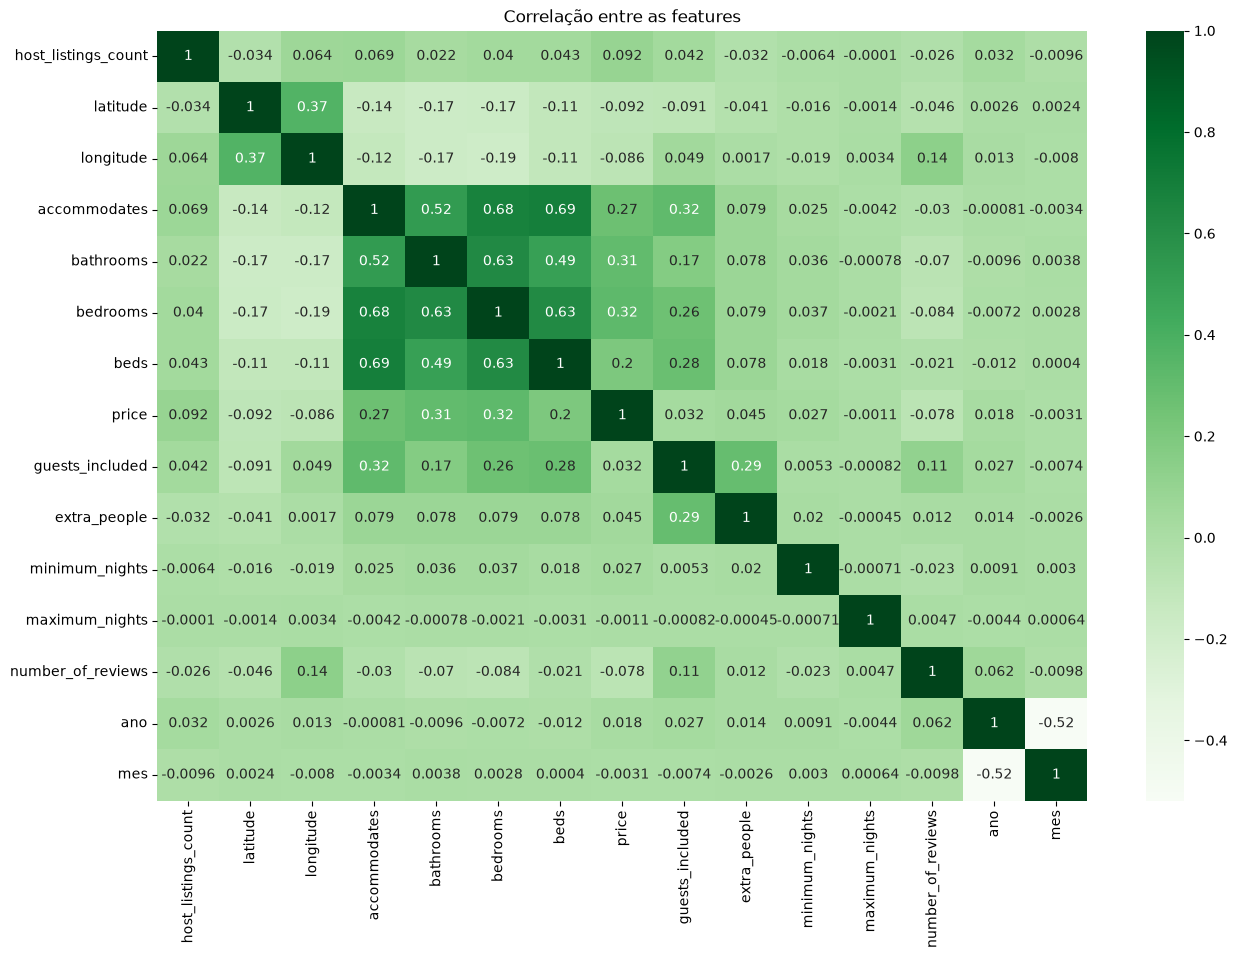

In [14]:
#ver a correlação entre as features e decidir se manteremos todas as features que temos.
#Features são as colunas do df, e a target é a coluna que queremos prever, no caso price.
#numeric_only=True para pegar somente as colunas numéricas.
#print(base_airbnb2.corr(numeric_only=True))
plt.figure(figsize=(15,10))
plt.title('Correlação entre as features')
sns.heatmap(base_airbnb2.corr(numeric_only=True), annot=True, cmap='Greens')


### Definição de Funções para Análise de Outliers

 - Vamos definir algumas funções para ajudar na análise de outliers das colunas

In [15]:
#Excluir outliers (usaremos como regra, valores abaixo de Q1 - 1.5xAmplitude e valores acima de Q3 + 1.5x Amplitude). Amplitude = Q3 - Q1

def limites(coluna):
    q1 = coluna.quantile(0.25)
    q3 = coluna.quantile(0.75)
    amplitude = q3 - q1
    limite_inferior = q1 - 1.5 * amplitude
    limite_superior = q3 + 1.5 * amplitude
    return limite_inferior, limite_superior

print(limites(base_airbnb2['price']))

def excluir_outliers(df, nome_coluna):
    qtde_linhas = df.shape[0]
    limite_inferior, limite_superior = limites(df[nome_coluna])
    df = df[(df[nome_coluna] >= limite_inferior) & (df[nome_coluna] <= limite_superior)]
    linhas_removidas = qtde_linhas - df.shape[0]
    return df, linhas_removidas

(np.float64(-524.0), np.float64(1276.0))


In [16]:
def diagrama_caixa(coluna):
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(15, 5)
    sns.boxplot(x=coluna, ax=ax1)
    ax2.set_xlim(limites(coluna))
    sns.boxplot(x=coluna, ax=ax2)   

def histograma(coluna):
    plt.figure(figsize=(15,5))
    sns.histplot(coluna, bins=40, kde=True)

def grafico_barras(coluna):
    plt.figure(figsize=(15, 5))
    
    # 1. Filtra os valores contados que estão dentro dos limites desejados
    counts = coluna.value_counts().sort_index()
    lim_min, lim_max = limites(coluna)
    counts_filtrado = counts[(counts.index >= lim_min) & (counts.index <= lim_max)]
    
    # 2. Plota apenas as barras dentro do limite
    ax = sns.barplot(x=counts_filtrado.index, y=counts_filtrado.values)    
       
    # 3. Adiciona margem superior para o texto não ser cortado no topo
    ax.set_ylim(top=ax.get_ylim()[1] * 1.15)
    
    # 4. Adiciona os rótulos acima de cada barra
    ax.bar_label(ax.containers[0], padding=3)



### Price

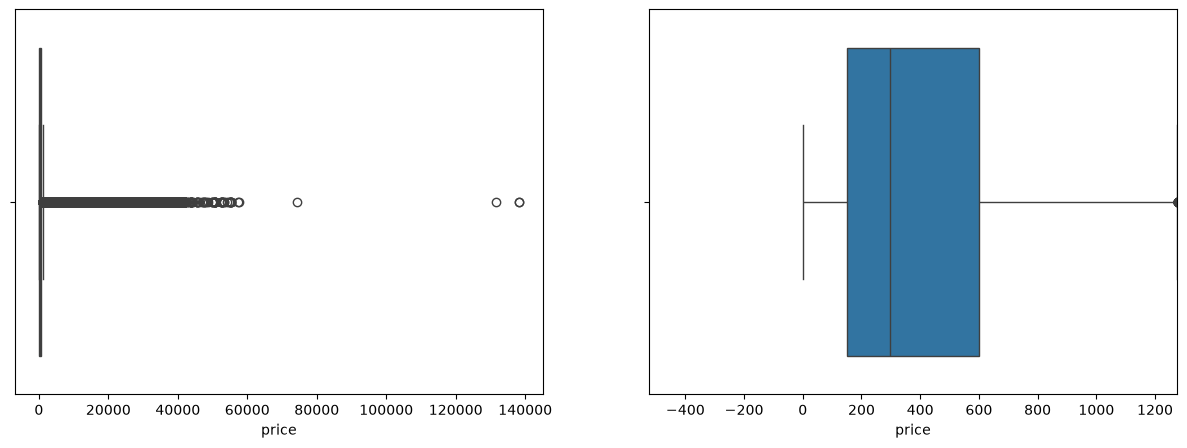

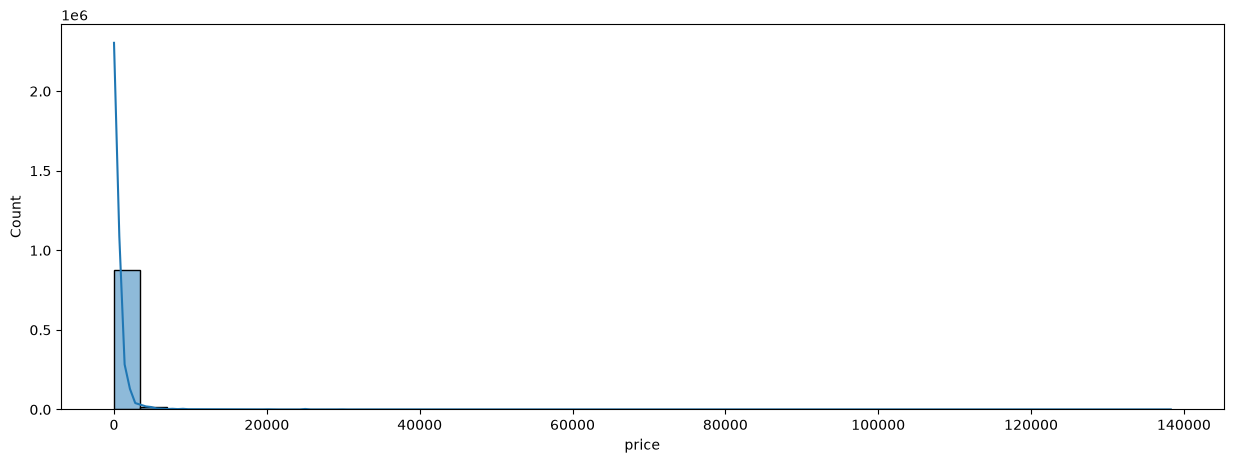

In [17]:
diagrama_caixa(base_airbnb2['price'])
histograma(base_airbnb2['price'])

Como estamos construindo um modelo para imóveis comuns, acredito que os valores acima do limite superior serão apenas de imóveis de altíssimo luxo, que não é o nosso objetivo principal. Por isso podemos excluir esses outliers

In [18]:
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'price')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna price.')

Foram removidas 87282 linhas com outliers na coluna price.


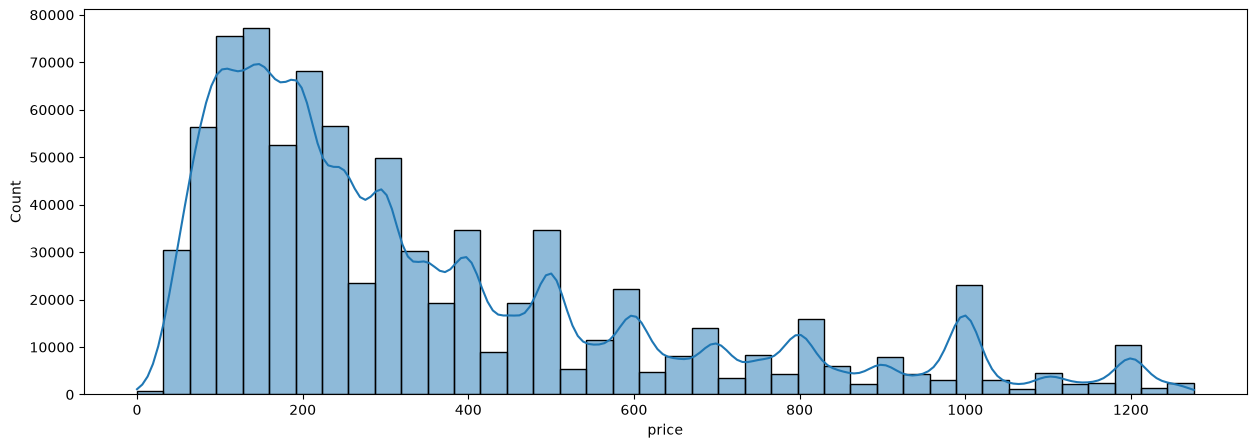

In [19]:
histograma(base_airbnb2['price'])

### extra_people                

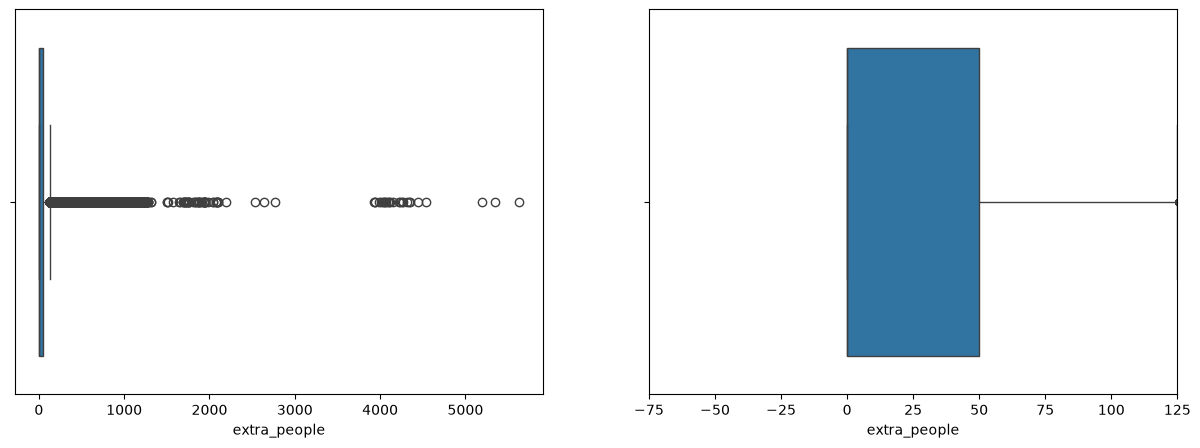

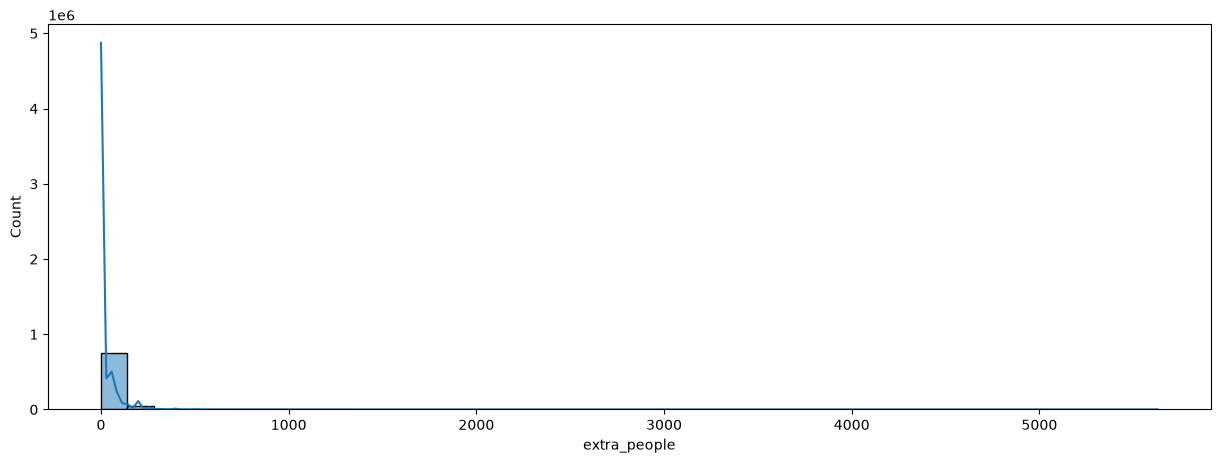

In [20]:
diagrama_caixa(base_airbnb2['extra_people'])
histograma(base_airbnb2['extra_people'])

vamos excluir os outliers da coluna extra_people, talvez depois ver como fica o modelo com esses dados

In [21]:
#vamos excluir os outliers da coluna extra_people, talvez depois ver como fica o modelo com esses dados
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'extra_people')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna extra_people.')


Foram removidas 59194 linhas com outliers na coluna extra_people.


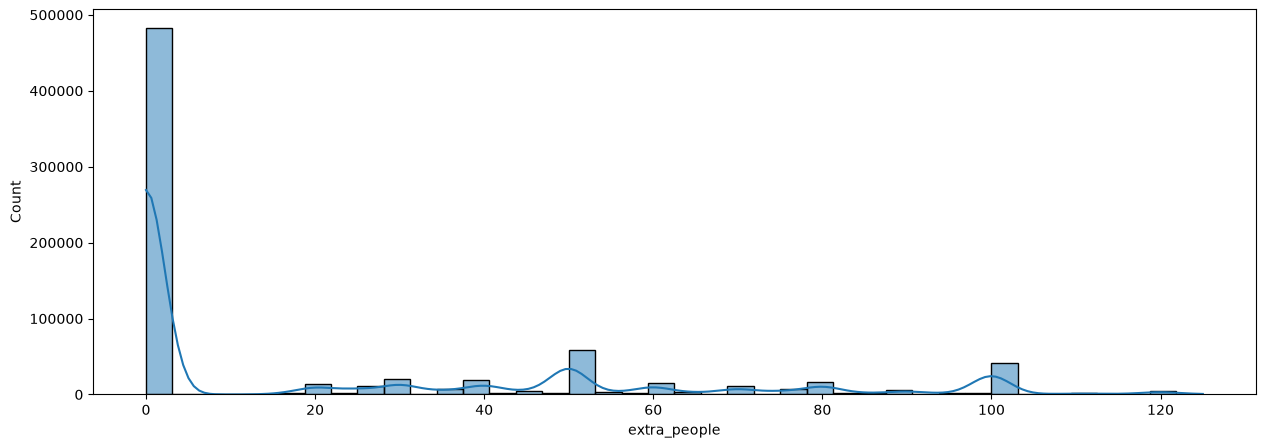

In [22]:
histograma(base_airbnb2['extra_people'])

### host_listings_count

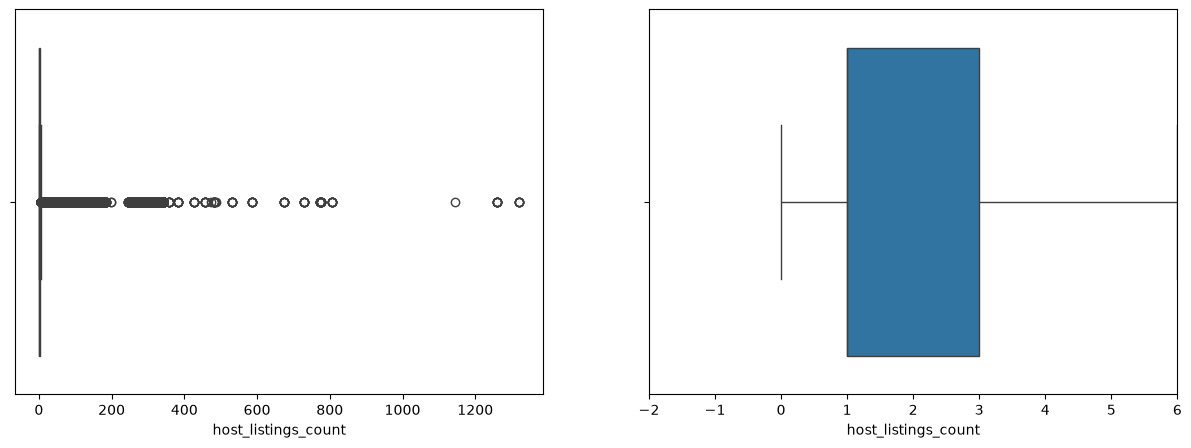

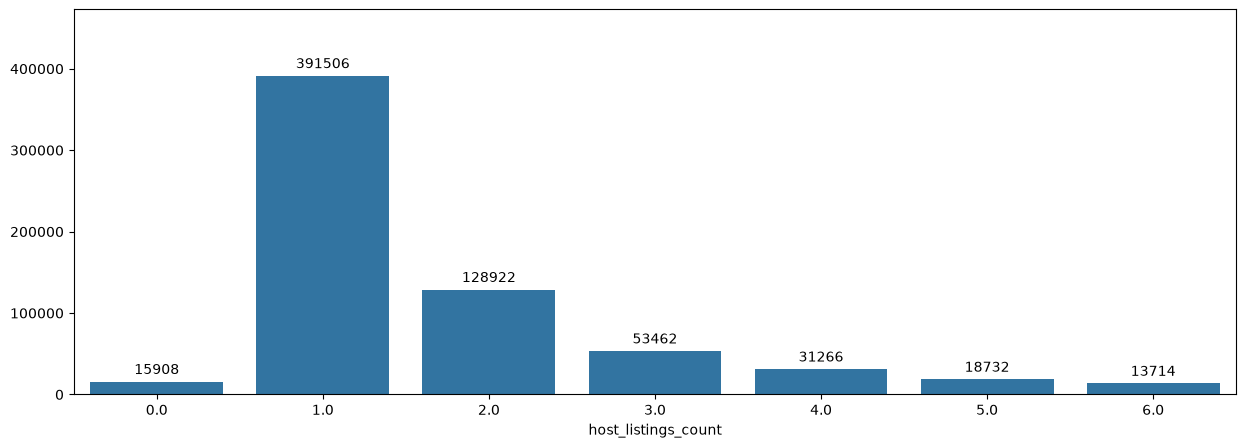

In [23]:
diagrama_caixa(base_airbnb2['host_listings_count'])
grafico_barras(base_airbnb2['host_listings_count'])

podemos excluir os outliers de host_listings_count porque hosts com mais de 6 imóveis no Airbnb não são o público-alvo do projeto (imagino que seja imobiliárias ou profissionais que gerenciam imóveis no airbnb)

Foram removidas 97723 linhas com outliers na coluna host_listings_count.


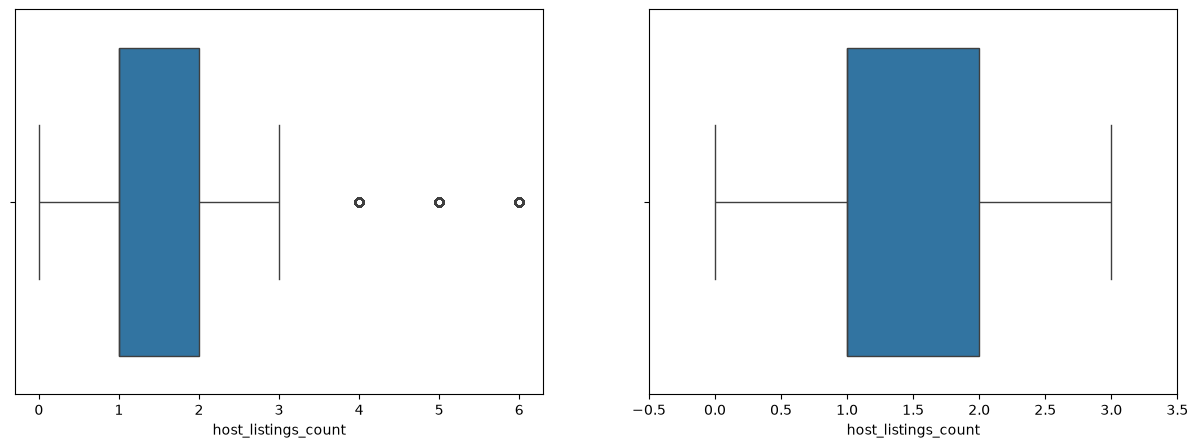

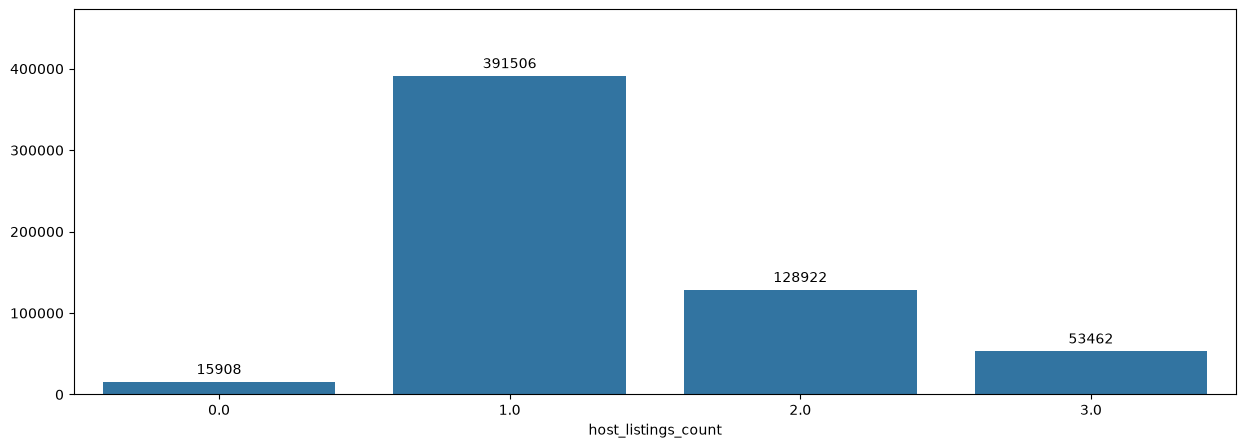

In [24]:
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'host_listings_count')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna host_listings_count.')

diagrama_caixa(base_airbnb2['host_listings_count'])
grafico_barras(base_airbnb2['host_listings_count'])

### accommodates

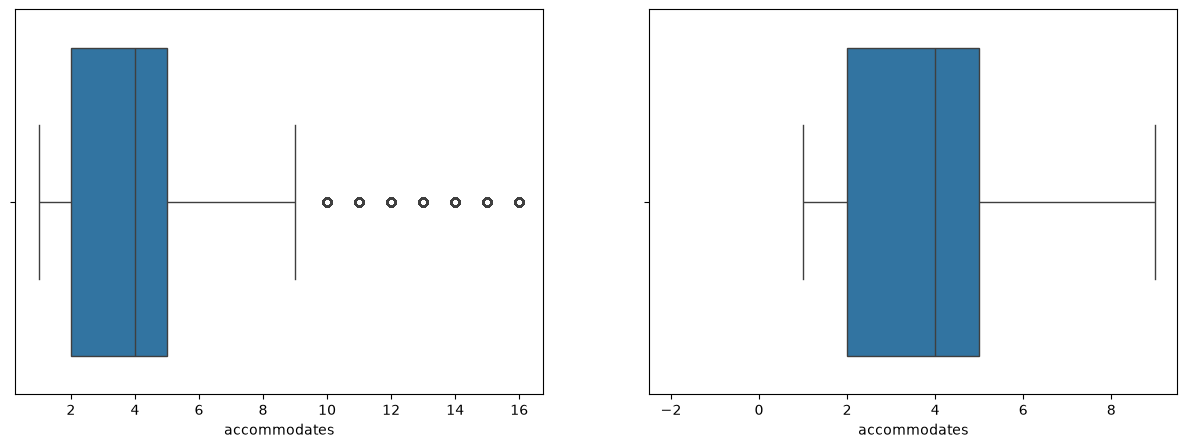

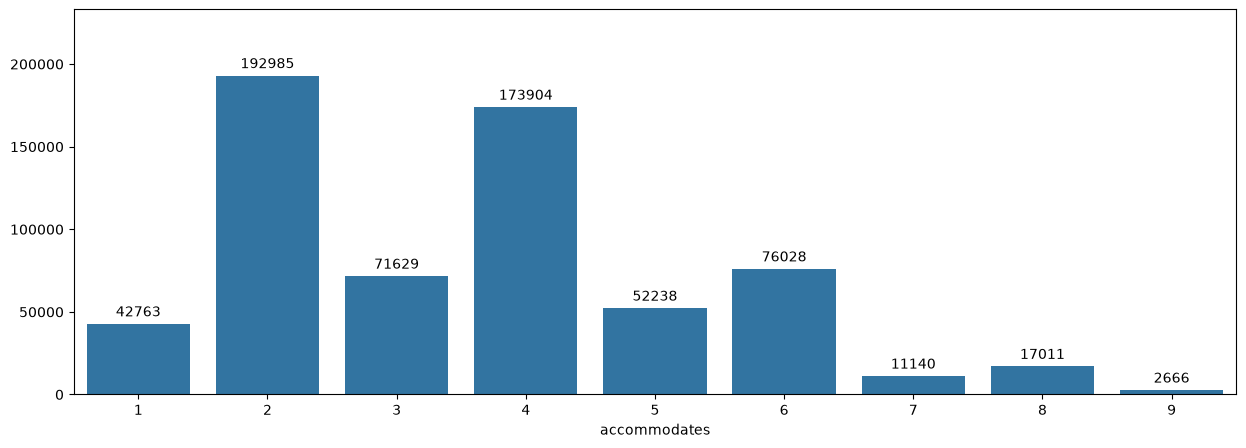

In [25]:
diagrama_caixa(base_airbnb2['accommodates'])
grafico_barras(base_airbnb2['accommodates'])

Foram removidas 13146 linhas com outliers na coluna accommodates.


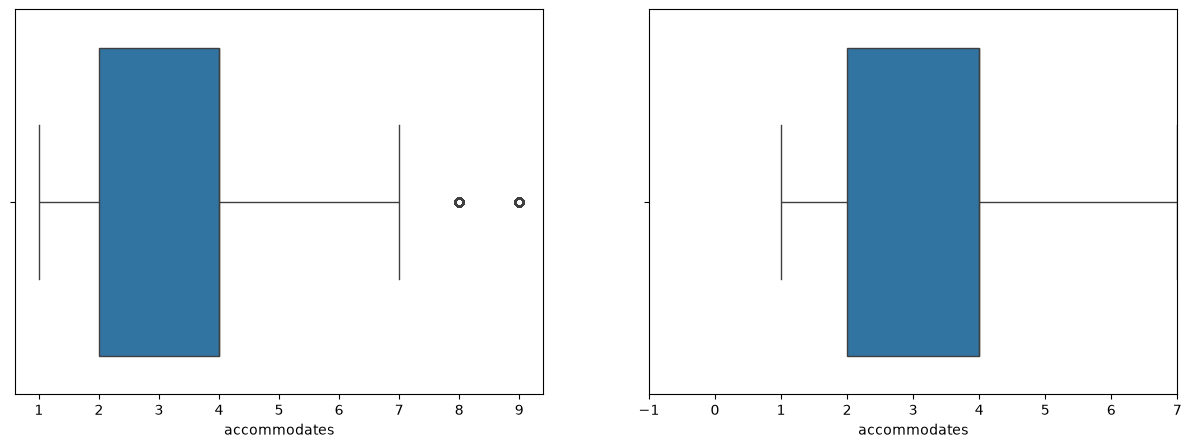

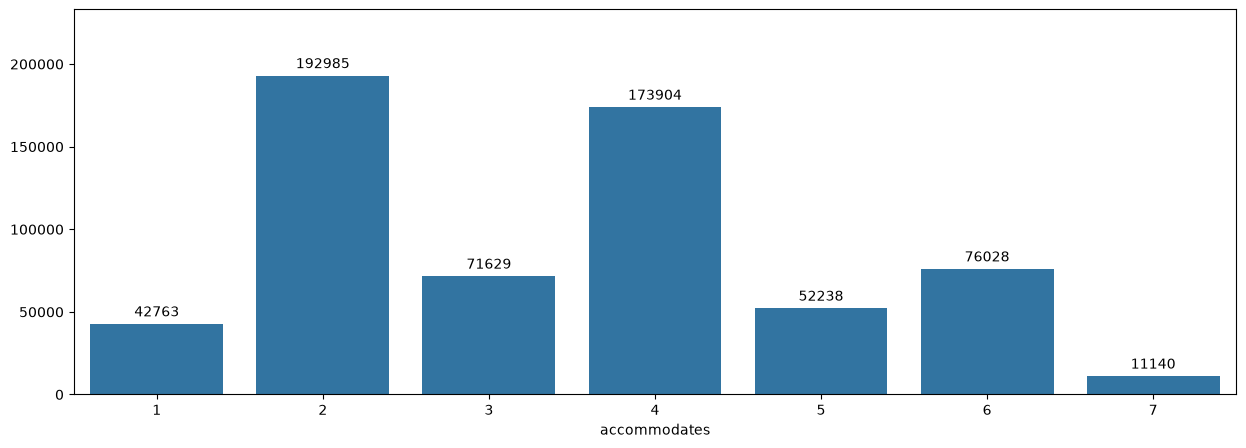

In [26]:
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'accommodates')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna accommodates.')

diagrama_caixa(base_airbnb2['accommodates'])
grafico_barras(base_airbnb2['accommodates'])

### bathrooms

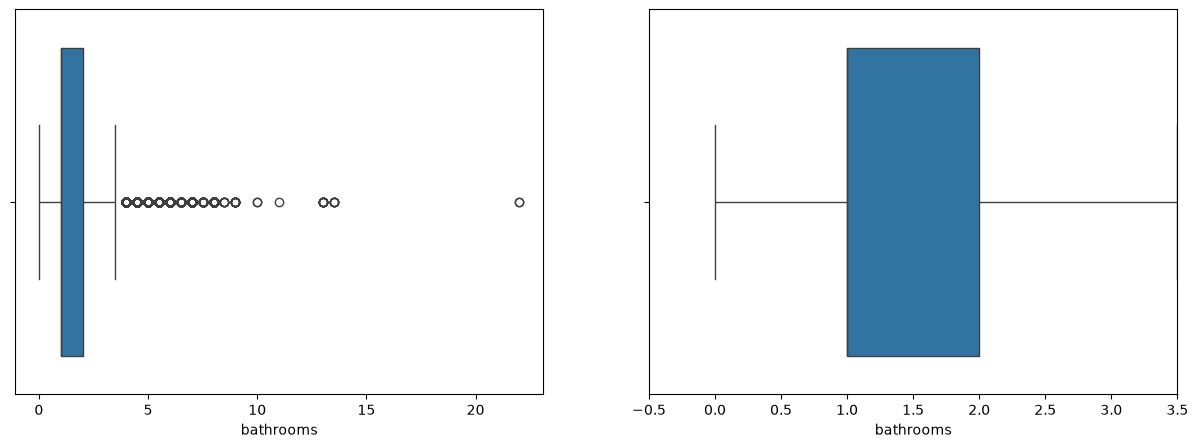

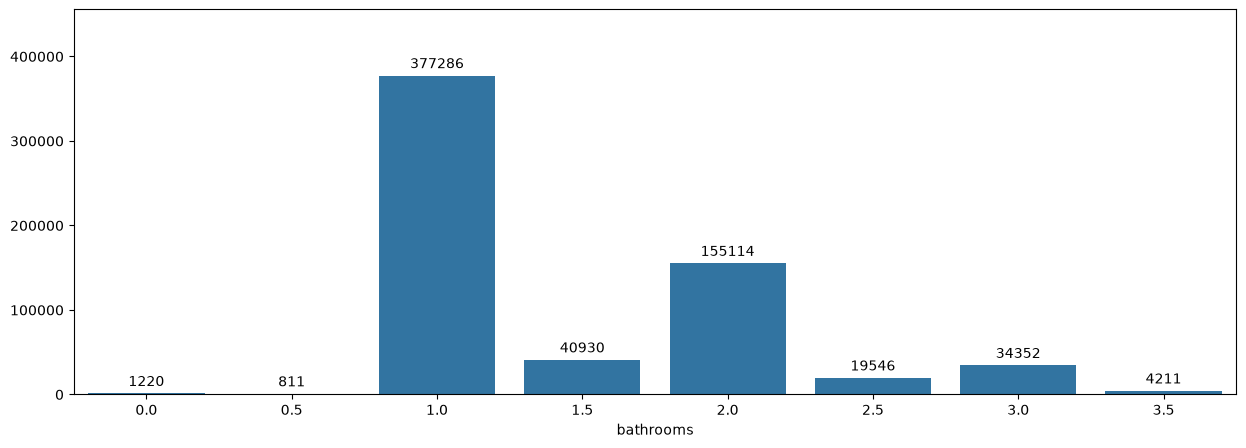

In [27]:
diagrama_caixa(base_airbnb2['bathrooms'])
grafico_barras(base_airbnb2['bathrooms'])

Foram removidas 6894 linhas com outliers na coluna bathrooms.


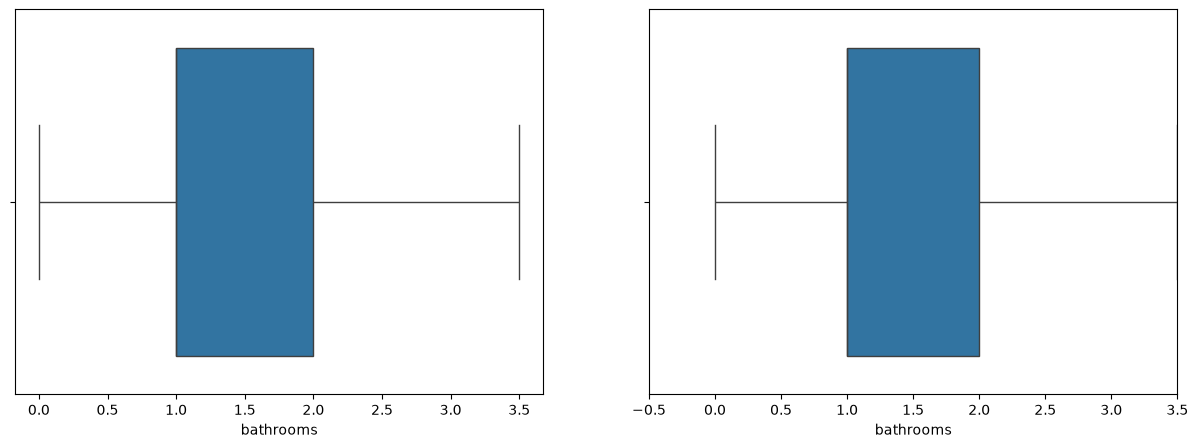

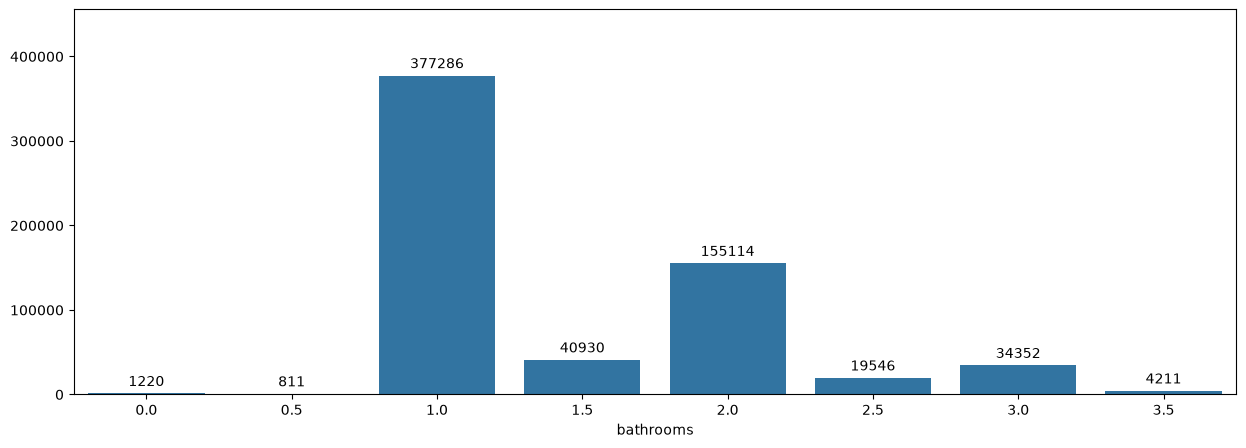

In [28]:
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'bathrooms')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna bathrooms.')

diagrama_caixa(base_airbnb2['bathrooms'])
grafico_barras(base_airbnb2['bathrooms'])

### bedrooms

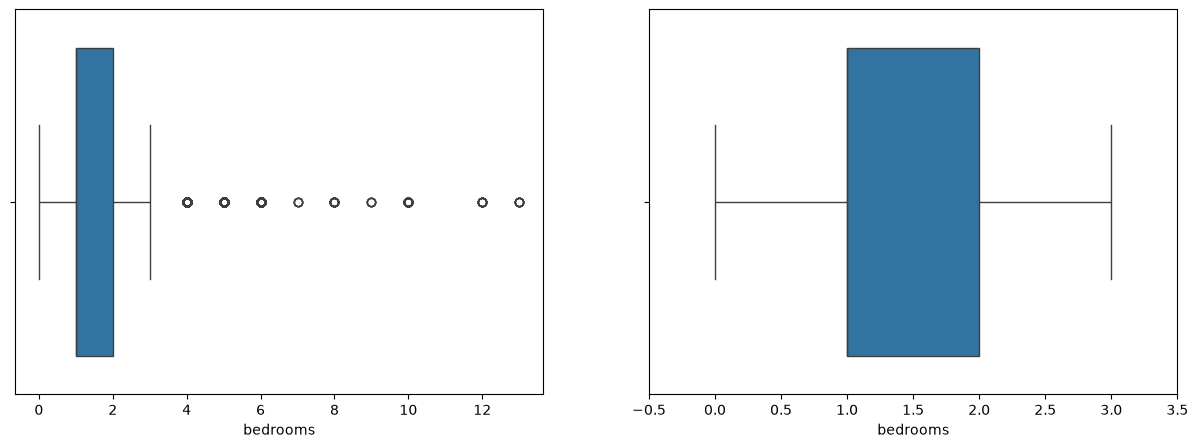

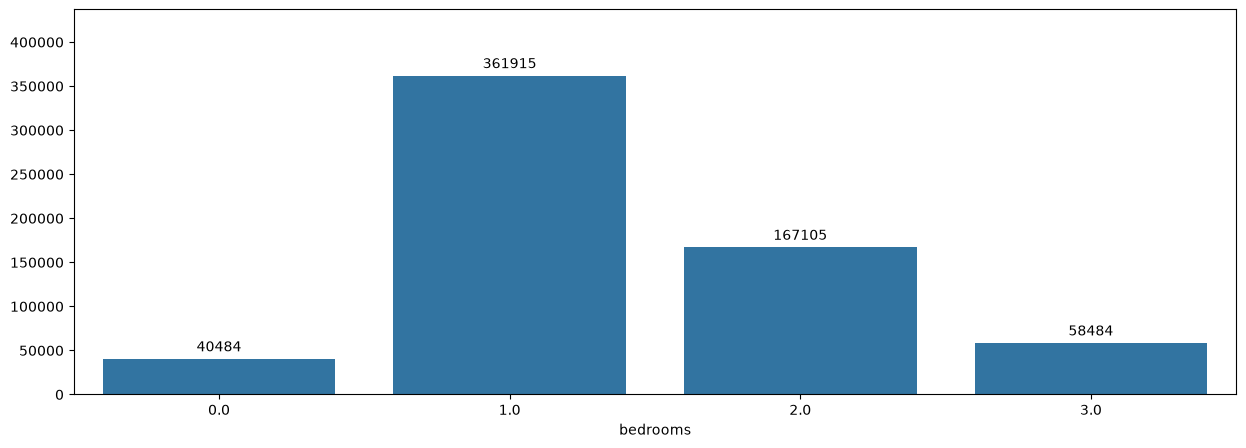

In [29]:
diagrama_caixa(base_airbnb2['bedrooms'])
grafico_barras(base_airbnb2['bedrooms'])


### beds

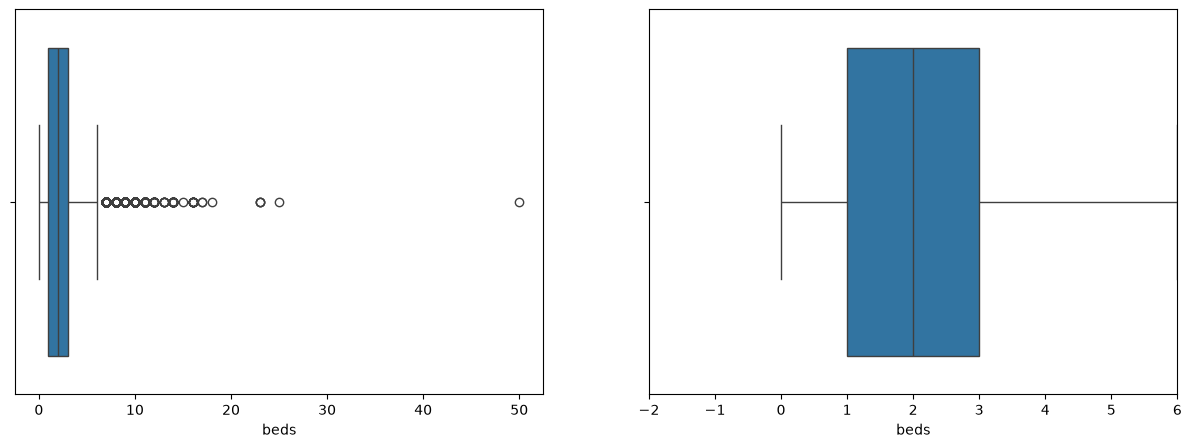

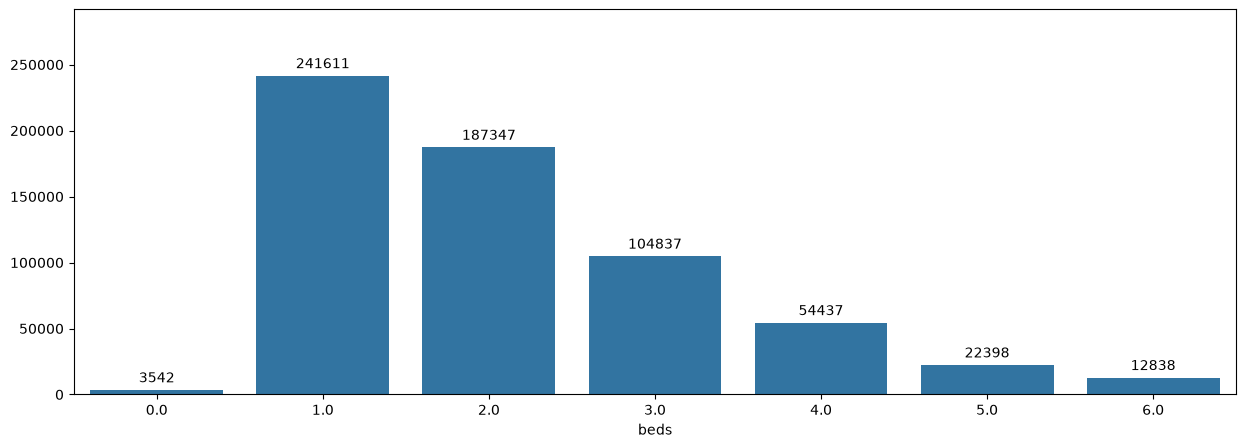

In [30]:
diagrama_caixa(base_airbnb2['beds'])
grafico_barras(base_airbnb2['beds'])

### guests_included

C:\Users\m_fan\AppData\Local\Temp\ipykernel_49212\1784110907.py:5: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax2.set_xlim(limites(coluna))


<Axes: xlabel='guests_included'>

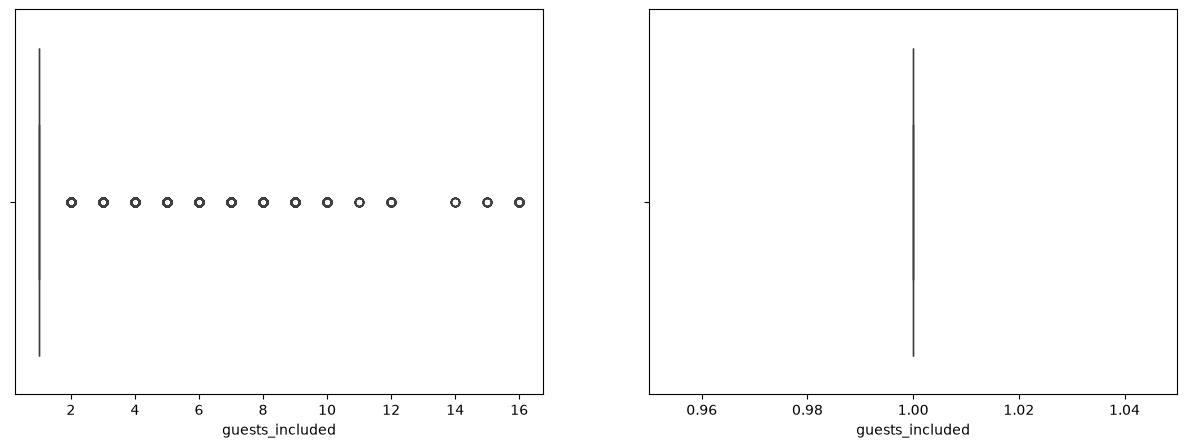

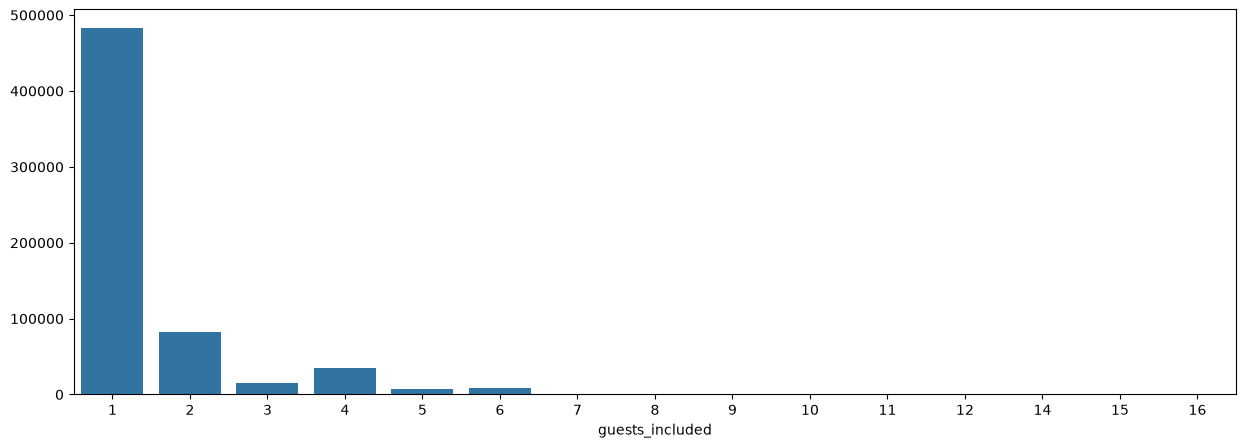

In [31]:
diagrama_caixa(base_airbnb2['guests_included'])
plt.figure(figsize=(15, 5))
sns.barplot(x=base_airbnb2['guests_included'].value_counts().index, y=base_airbnb2['guests_included'].value_counts().values)
#como neste caso deu uma mensagem de warning, fizemos um gráfico de barras diferente (direto com o value_counts, sem filtrar pelos limites).
#vimos que a maioria dos valores estão em 1, então é possível que seja uma coluna com erro de preenchimento, mas vamos manter por enquanto, pois pode ser que seja uma coluna que não tenha erro de preenchimento.


Vamos excluir a coluna, pois excluir os outliers pode dar algum problema. Parece que os usuários deixam o padrão do Airbnb (1). Isso pode levar o modelo a usar uma feature que não é essencial para a definição do preço. Por isso parece melhor excluir a coluna da análise

In [32]:
base_airbnb2 = base_airbnb2.drop(columns=['guests_included'])


In [33]:
print(base_airbnb2.shape)

(633470, 22)


### minimum_nights

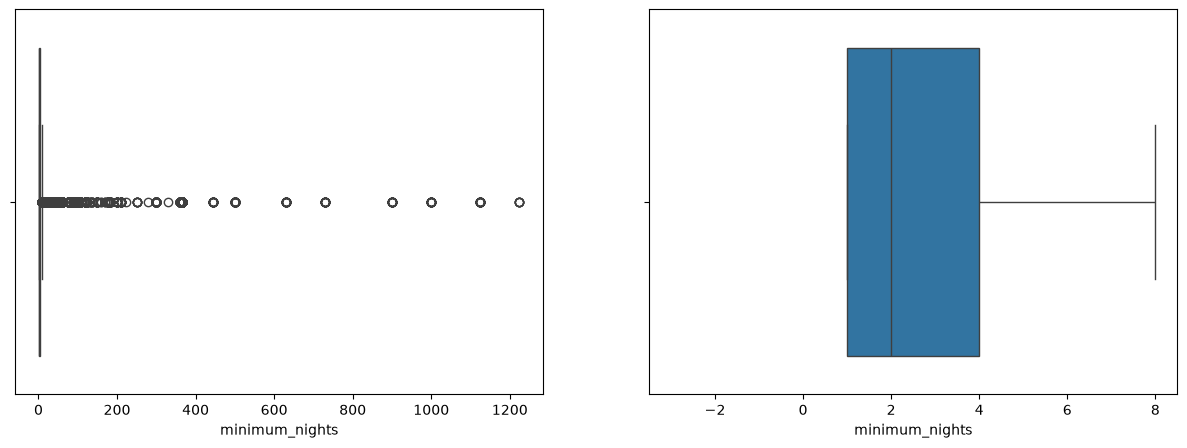

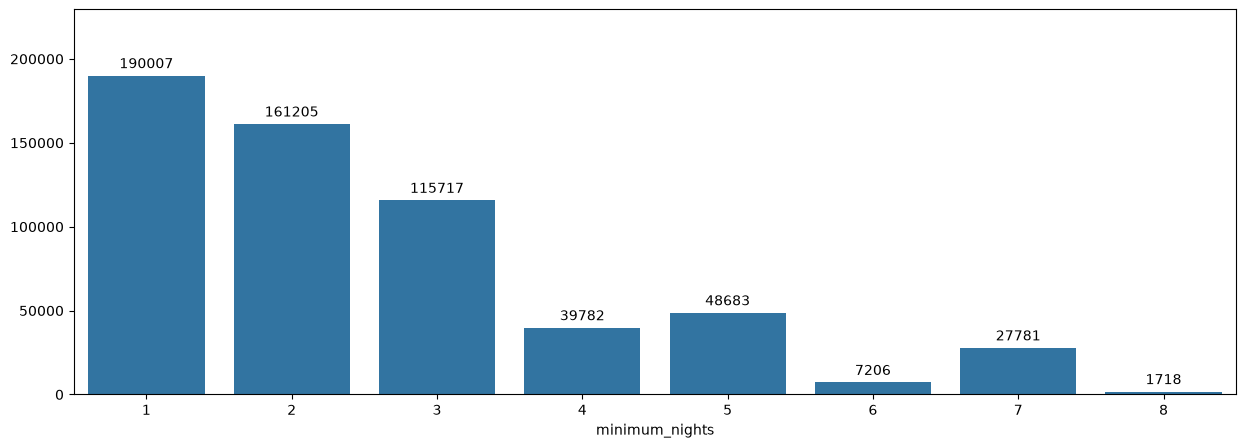

In [34]:
diagrama_caixa(base_airbnb2['minimum_nights'])
grafico_barras(base_airbnb2['minimum_nights'])

Foram removidas 41371 linhas com outliers na coluna minimum_nights.


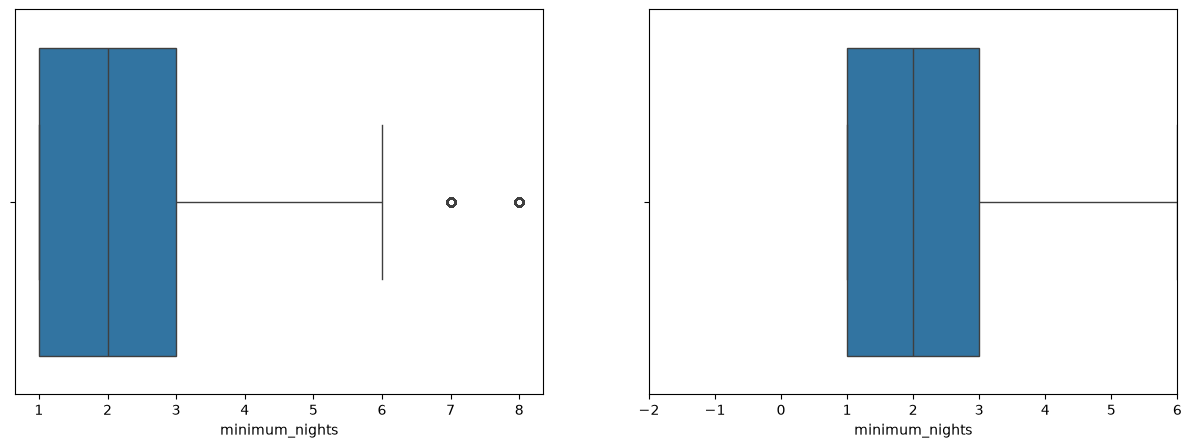

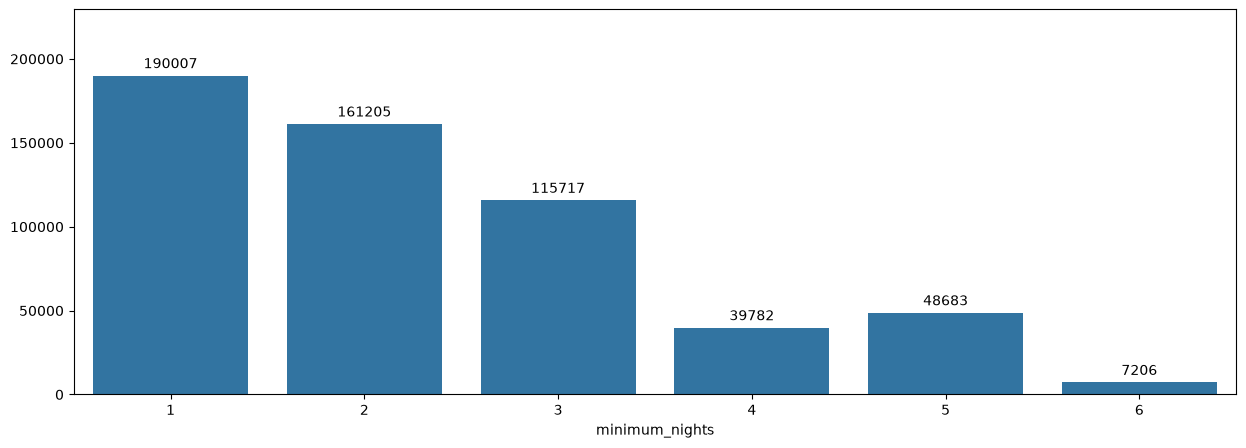

In [35]:
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'minimum_nights')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna minimum_nights.')

diagrama_caixa(base_airbnb2['minimum_nights'])
grafico_barras(base_airbnb2['minimum_nights'])

### maximum_nights

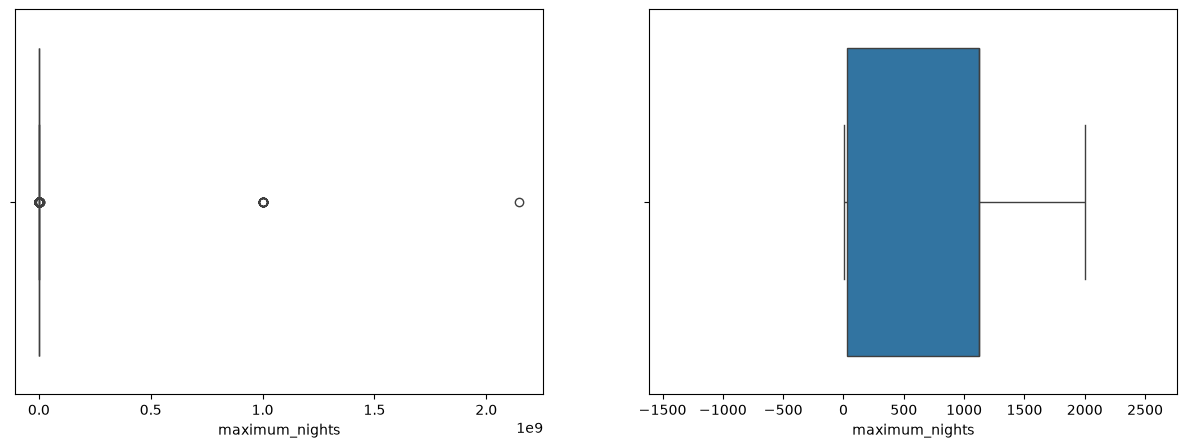

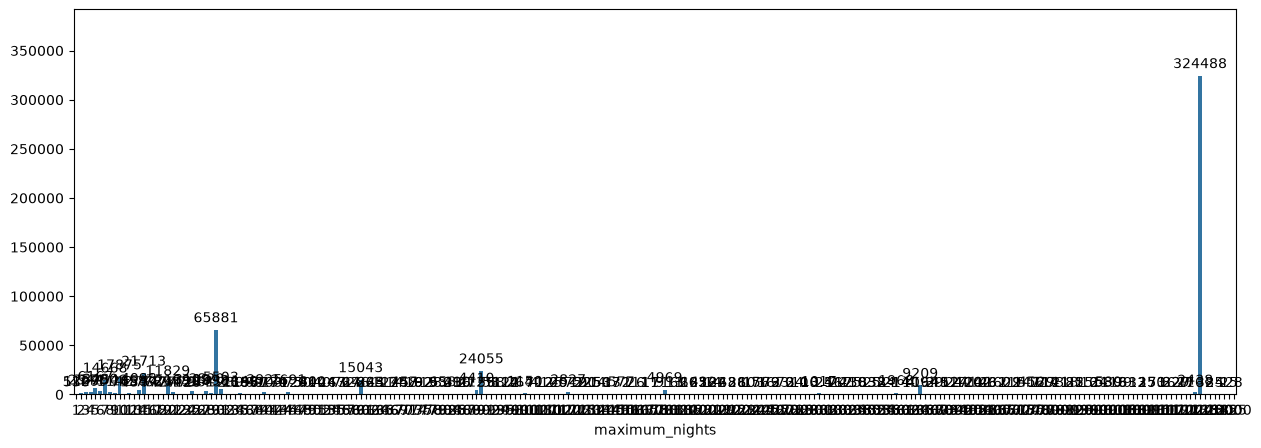

In [36]:
diagrama_caixa(base_airbnb2['maximum_nights'])
grafico_barras(base_airbnb2['maximum_nights'])

maximum_nights também parece ter valores fora do normal, preenchidos com o valor padrão 0 e também com valores muito altos. Por isso vamos excluir a coluna da análise (talvez depois ver como fica o modelo com ela)

In [37]:
base_airbnb2 = base_airbnb2.drop(columns=['maximum_nights'])
print(base_airbnb2.shape)

(592099, 21)


### number_of_reviews

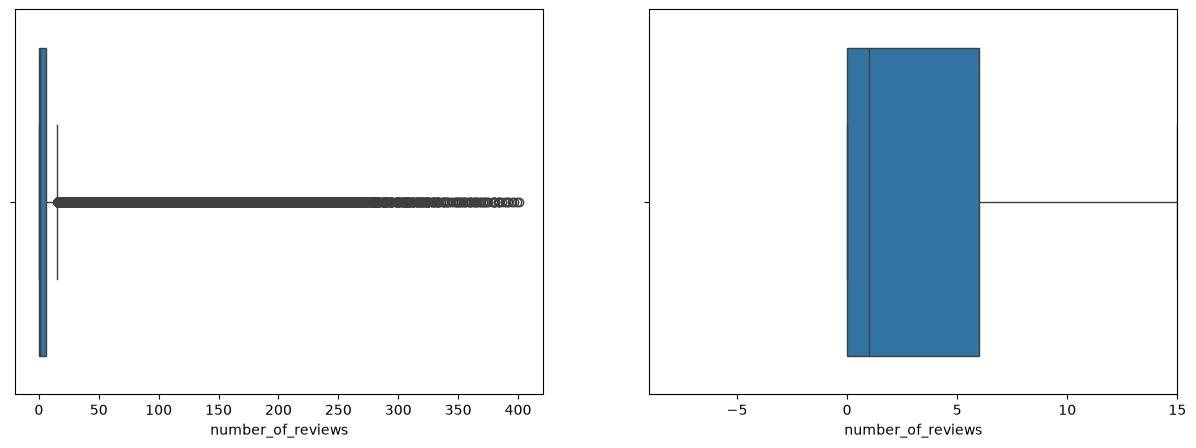

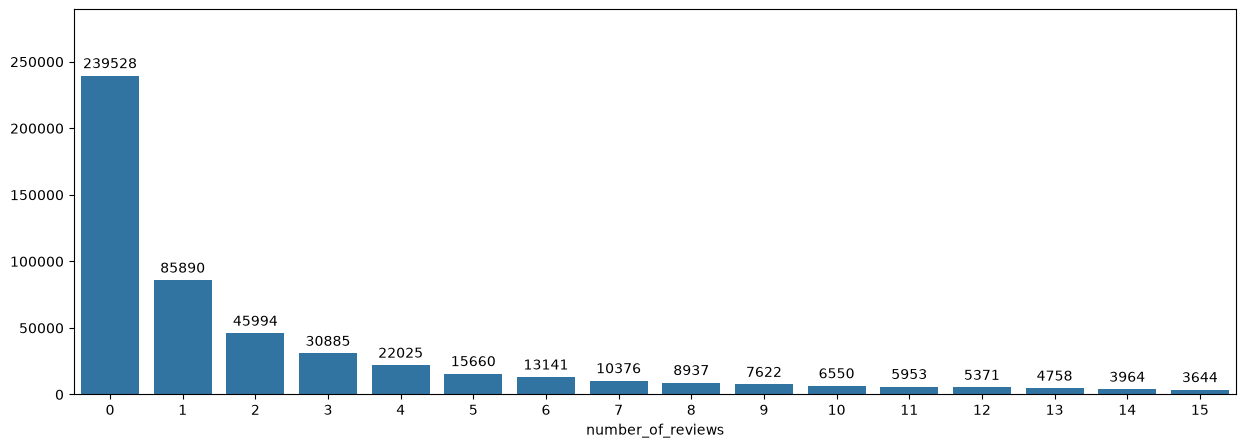

In [38]:
diagrama_caixa(base_airbnb2['number_of_reviews'])
grafico_barras(base_airbnb2['number_of_reviews'])

Se excluirmos os outliers de number_of_reviews vamos retirar os anúncios mais antigos, que são os que têm mais reviews. Além disso, quem não tem reviews é anúncio novo, e esse também é o público que quer saber quanto cobrar. Por isso a coluna será excluída da análise.

In [39]:
base_airbnb2 = base_airbnb2.drop(columns=['number_of_reviews'])
print(base_airbnb2.shape)

(592099, 20)


### Tratamento de colunas com valores de texto

- property_type

property_type
Apartment                 465416
House                      53149
Condominium                27135
Serviced apartment         12700
Loft                       12359
Bed and breakfast           3662
Guest suite                 3644
Hostel                      2705
Guesthouse                  2234
Other                       1975
Villa                       1330
Townhouse                    976
Aparthotel                   709
Earth house                  491
Chalet                       490
Boutique hotel               474
Tiny house                   457
Hotel                        379
Casa particular (Cuba)       304
Cottage                      259
Bungalow                     240
Dorm                         186
Cabin                        151
Nature lodge                 131
Castle                        80
Treehouse                     76
Island                        64
Boat                          53
Hut                           40
Campsite                     

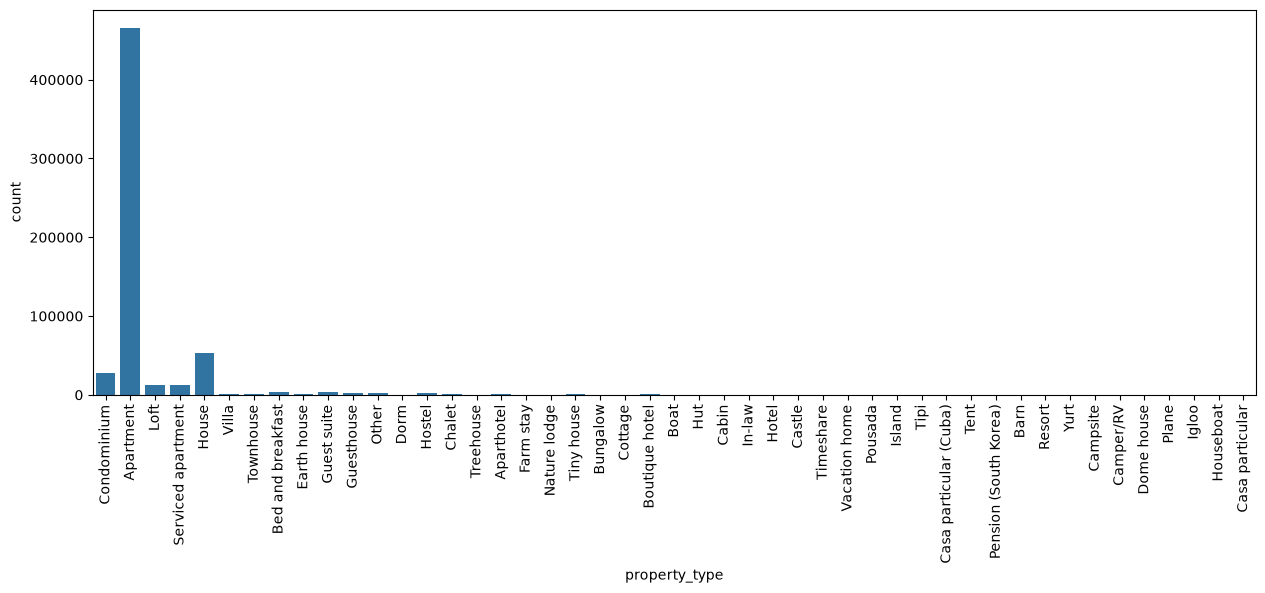

In [40]:
print(base_airbnb2['property_type'].value_counts())
plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='property_type', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)

property_type
Apartment             465416
House                  53149
Condominium            27135
Serviced apartment     12700
Loft                   12359
Outros                  9095
Bed and breakfast       3662
Guest suite             3644
Hostel                  2705
Guesthouse              2234
Name: count, dtype: int64


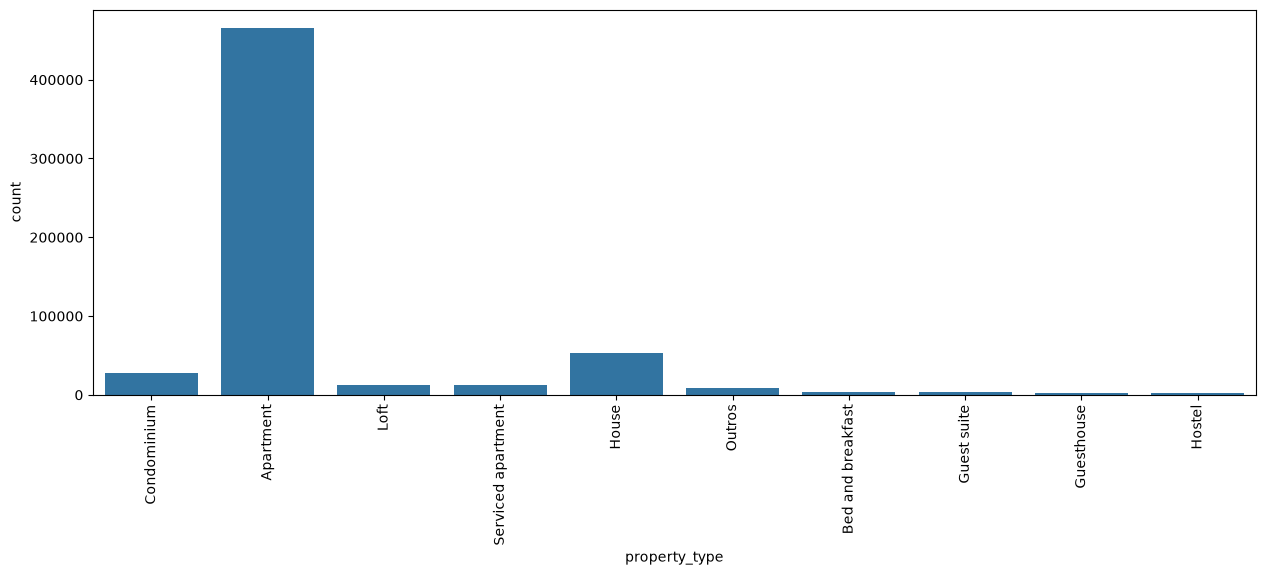

In [41]:
tabela_tipos_casa = base_airbnb2['property_type'].value_counts()
colunas_agrupar = []
for tipo in tabela_tipos_casa.index:
    if tabela_tipos_casa[tipo] < 2000:
        colunas_agrupar.append(tipo)

for tipo in colunas_agrupar:
    base_airbnb2.loc[base_airbnb2['property_type'] == tipo, 'property_type'] = 'Outros'

print(base_airbnb2['property_type'].value_counts())

plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='property_type', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)


- room_type

room_type
Entire home/apt    380990
Private room       197725
Shared room         12409
Hotel room            975
Name: count, dtype: int64


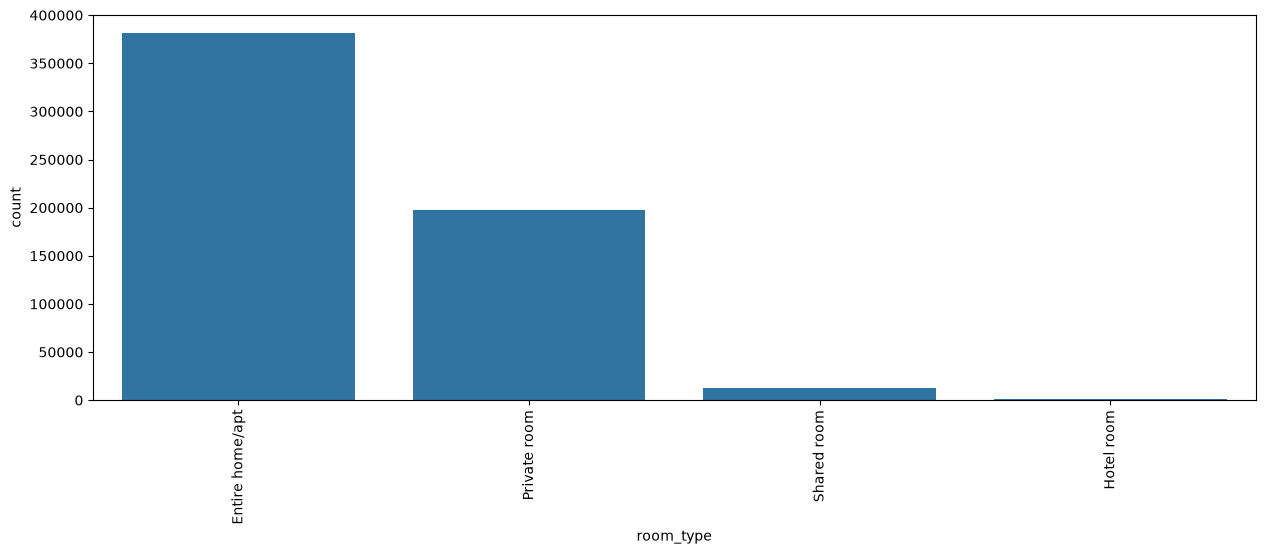

In [42]:
print(base_airbnb2['room_type'].value_counts())
plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='room_type', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)
#não será necessário agrupar os tipos de room_type, pois são poucos tipos e a quantidade de cada tipo é grande.

- bed_type                        

bed_type
Real Bed         580746
Pull-out Sofa      8055
Futon              1634
Airbed             1155
Couch               509
Name: count, dtype: int64


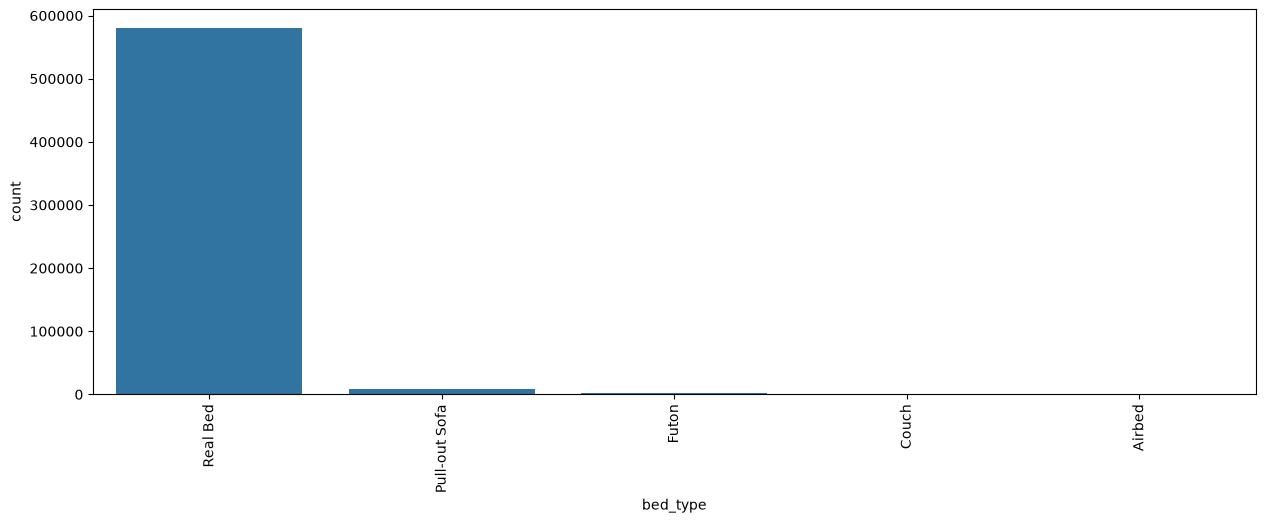

In [43]:
print(base_airbnb2['bed_type'].value_counts())
plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='bed_type', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)             


bed_type
Real Bed    580746
Outros       11353
Name: count, dtype: int64


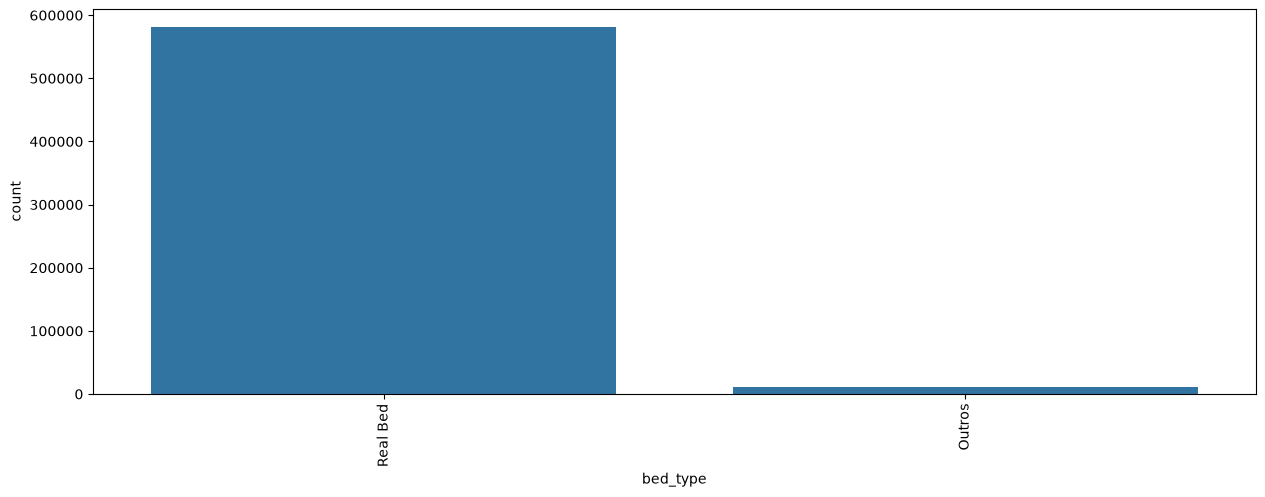

In [44]:
#aqui será necessário agrupar porque a quantidade de valores de alguns é muito pequena, 
# então vamos agrupar em Outros tipos de camas com valores menores que 10000 
tabela_bed_type = base_airbnb2['bed_type'].value_counts()
colunas_agrupar = []
for tipo in tabela_bed_type.index:
    if tabela_bed_type[tipo] < 10000:
        colunas_agrupar.append(tipo)

for tipo in colunas_agrupar:
    base_airbnb2.loc[base_airbnb2['bed_type'] == tipo, 'bed_type'] = 'Outros'

print(base_airbnb2['bed_type'].value_counts())

plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='bed_type', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)

- cancellation_policy

cancellation_policy
flexible                       261847
strict_14_with_grace_period    205300
moderate                       114860
strict                           9919
super_strict_60                   135
super_strict_30                    38
Name: count, dtype: int64


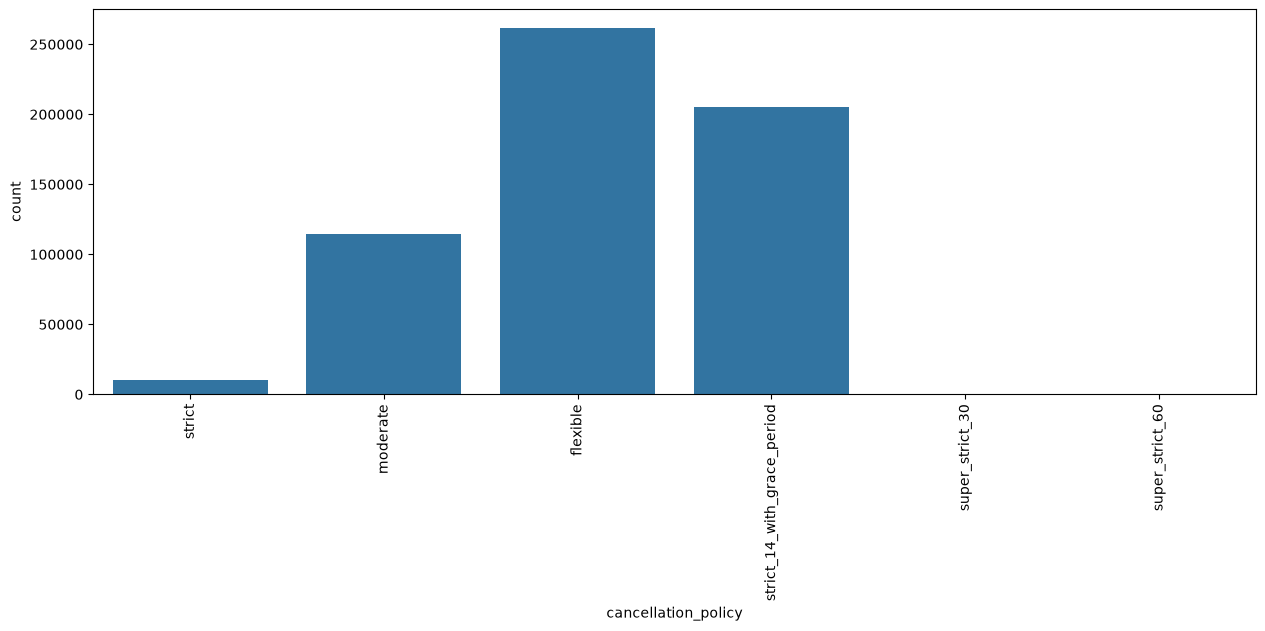

In [45]:
print(base_airbnb2['cancellation_policy'].value_counts())
plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='cancellation_policy', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)

cancellation_policy
flexible                       261847
strict_14_with_grace_period    205300
moderate                       114860
strict                          10092
Name: count, dtype: int64


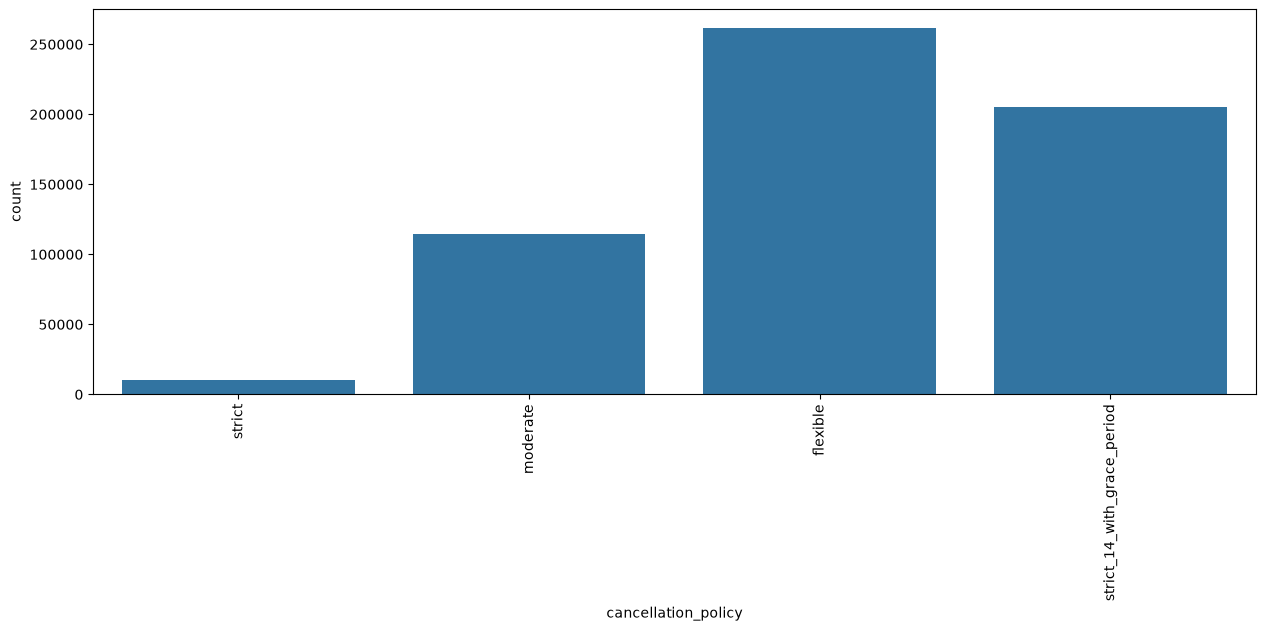

In [46]:
#aqui será necessário agrupar porque a quantidade de valores de alguns é muito pequena, 
# então vamos agrupar em strict com valores menores que 10000 
tabela_cancellation = base_airbnb2['cancellation_policy'].value_counts()
colunas_agrupar = []
for tipo in tabela_cancellation.index:
    if tabela_cancellation[tipo] < 10000:
        colunas_agrupar.append(tipo)

for tipo in colunas_agrupar:
    base_airbnb2.loc[base_airbnb2['cancellation_policy'] == tipo, 'cancellation_policy'] = 'strict'

print(base_airbnb2['cancellation_policy'].value_counts())

plt.figure(figsize=(15, 5))
grafico = sns.countplot(x='cancellation_policy', data=base_airbnb2)
grafico.tick_params(axis='x', rotation=90)

- amenities         
como temos uma diversidade muito grande de amenities e às vezes a mesma amenity pode ser escrita de formas diferentes, vamos avaliar a quantidade de amenities como parâmetro para o nosso modelo



In [47]:
# na coluna os itens estão separados por ',' então vamos separar tudo por virgula e contar os itens

print(base_airbnb2['amenities'].iloc[0].split(','))
print(len(base_airbnb2['amenities'].iloc[0].split(',')))

#criar uma coluna com o numero dos amenities e depois excluir a coluna amenities

base_airbnb2['qtde_amenities'] = base_airbnb2['amenities'].str.split(',').apply(len)

base_airbnb2 = base_airbnb2.drop(columns=['amenities'])
display(base_airbnb2)



['{TV', '"Cable TV"', 'Internet', 'Wifi', '"Air conditioning"', 'Kitchen', '"Paid parking off premises"', '"Smoking allowed"', 'Doorman', 'Elevator', '"Hot tub"', '"Family/kid friendly"', '"Suitable for events"', 'Essentials', '"24-hour check-in"', 'Hangers', '"Hair dryer"', 'Iron', '"Laptop friendly workspace"', '"Self check-in"', '"Front desk/doorperson"', '"Private entrance"', '"Hot water"', '"Bed linens"', '"Luggage dropoff allowed"}']
25


,host_is_superhost,host_listings_count,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,price,extra_people,minimum_nights,instant_bookable,is_business_travel_ready,cancellation_policy,ano,mes,qtde_amenities
1,t,2.0,-22.965919,-43.178962,Condominium,Entire home/apt,5,1.0,2.0,2.0,Real Bed,270.0,51.0,4,t,f,strict,2018,4,25
3,f,3.0,-22.977117,-43.190454,Apartment,Entire home/apt,3,1.0,1.0,2.0,Real Bed,161.0,45.0,4,f,f,strict,2018,4,14
4,t,1.0,-22.983024,-43.214270,Apartment,Entire home/apt,3,1.0,1.0,2.0,Real Bed,222.0,68.0,2,t,f,strict,2018,4,16
5,t,1.0,-22.988165,-43.193588,Apartment,Entire home/apt,3,1.5,1.0,2.0,Real Bed,308.0,86.0,2,f,f,strict,2018,4,30
6,t,1.0,-22.981269,-43.190457,Loft,Entire home/apt,2,1.0,1.0,2.0,Real Bed,219.0,80.0,3,t,f,strict,2018,4,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
902204,f,1.0,-22.986030,-43.191660,Apartment,Entire home/apt,4,2.0,2.0,3.0,Real Bed,250.0,0.0,1,f,f,flexible,2019,9,15
902205,f,0.0,-23.003180,-43.342840,Apartment,Entire home/apt,4,1.0,0.0,2.0,Real Bed,121.0,50.0,1,f,f,flexible,2019,9,18
902206,f,0.0,-22.966640,-43.393450,Apartment,Entire home/apt,4,2.0,2.0,3.0,Real Bed,799.0,0.0,2,f,f,flexible,2019,9,12
902208,f,0.0,-23.003400,-43.341820,Apartment,Entire home/apt,4,1.0,1.0,1.0,Real Bed,250.0,0.0,1,f,f,strict_14_with_grace_period,2019,9,25


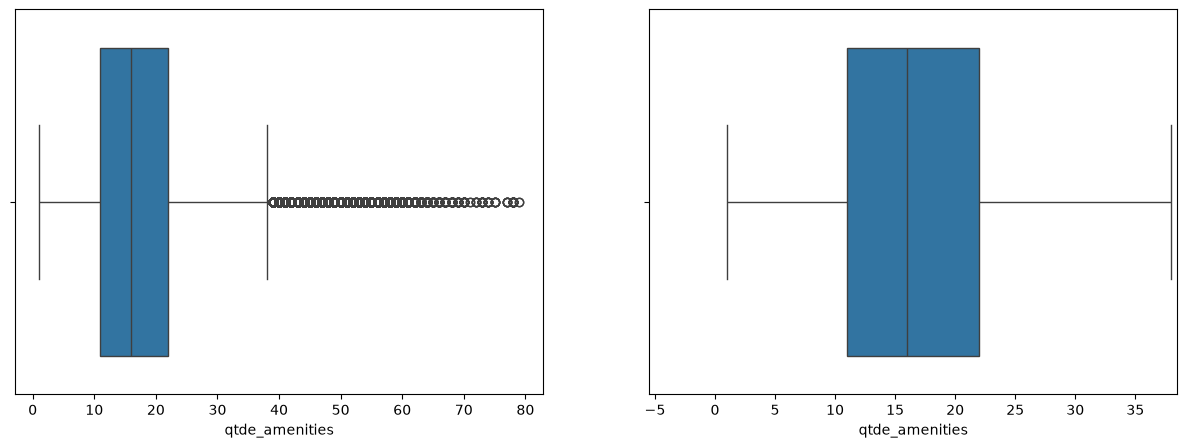

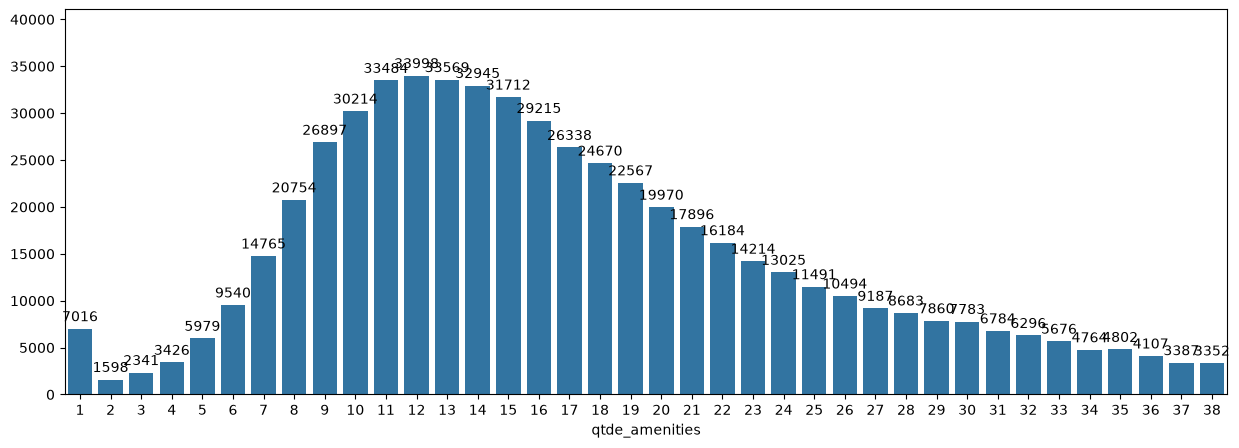

In [48]:
diagrama_caixa(base_airbnb2['qtde_amenities'])
grafico_barras(base_airbnb2['qtde_amenities'])

Foram removidas 25116 linhas com outliers na coluna qtde_amenities.


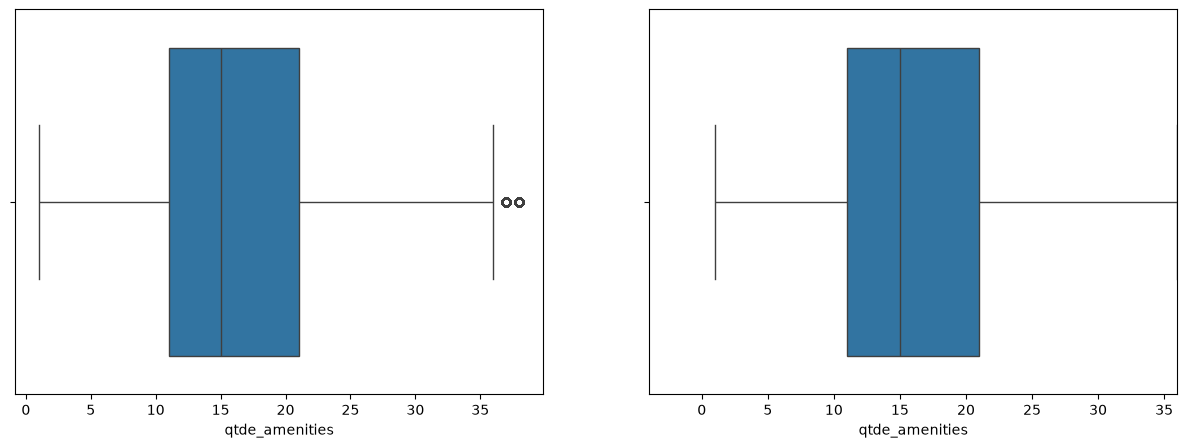

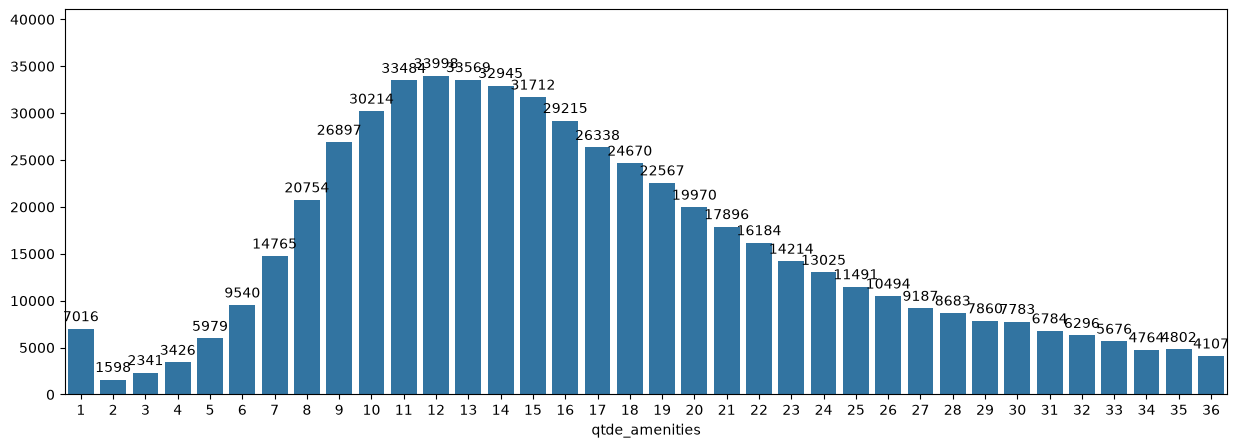

In [49]:
base_airbnb2, linhas_removidas = excluir_outliers(base_airbnb2, 'qtde_amenities')
print(f'Foram removidas {linhas_removidas} linhas com outliers na coluna qtde_amenities.')

diagrama_caixa(base_airbnb2['qtde_amenities'])
grafico_barras(base_airbnb2['qtde_amenities'])

### Visualização de mapa das propriedades

In [50]:
amostra = base_airbnb2.sample(n=50000)

centro_mapa = {'lat': amostra.latitude.mean(), 'lon': amostra.longitude.mean()}

mapa = px.density_map(
    amostra, lat='latitude', lon='longitude', z='price',
    radius=1,
    center=centro_mapa, zoom=10,
    map_style="open-street-map",
    #map_style="carto-positron",
    color_continuous_scale="Plasma",    
    opacity=0.8,)
mapa.show()

### Encoding
Precisamos ajustar as features para facilitar o trabalho do modelo futuro (features de categorias true e false etc..)
- Features true e false vamos substituir True por 1 e False por 0
- Features de categoria (features em que os valores das colunas são textos) vamos utilizar o método de encoding de variáveis dummies


In [51]:
colunas_tf = ['host_is_superhost', 'instant_bookable', 'is_business_travel_ready']
base_airbnb_cod = base_airbnb2.copy()
#print(base_airbnb_cod.iloc[0])    
#print(base_airbnb_cod.dtypes)
for coluna in colunas_tf:
    #base_airbnb_cod.loc[linha, coluna]
    base_airbnb_cod.loc[base_airbnb_cod[coluna] == 't', coluna] = '1'
    base_airbnb_cod.loc[base_airbnb_cod[coluna] == 'f', coluna] = '0'

#print(base_airbnb_cod.iloc[0])    

#print(base_airbnb_cod.dtypes)



In [52]:
colunas_categorias = ['property_type', 'room_type', 'bed_type','cancellation_policy']
#pd.get_dummies(dataframe, colunas)
base_airbnb_cod = pd.get_dummies(data=base_airbnb_cod, columns=colunas_categorias)
display(base_airbnb_cod.head())
print(base_airbnb_cod.dtypes)

,host_is_superhost,host_listings_count,latitude,longitude,accommodates,bathrooms,bedrooms,beds,price,extra_people,...,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room,bed_type_Outros,bed_type_Real Bed,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict,cancellation_policy_strict_14_with_grace_period
1,1,2.0,-22.965919,-43.178962,5,1.0,2.0,2.0,270.0,51.0,...,True,False,False,False,False,True,False,False,True,False
3,0,3.0,-22.977117,-43.190454,3,1.0,1.0,2.0,161.0,45.0,...,True,False,False,False,False,True,False,False,True,False
4,1,1.0,-22.983024,-43.214270,3,1.0,1.0,2.0,222.0,68.0,...,True,False,False,False,False,True,False,False,True,False
5,1,1.0,-22.988165,-43.193588,3,1.5,1.0,2.0,308.0,86.0,...,True,False,False,False,False,True,False,False,True,False
6,1,1.0,-22.981269,-43.190457,2,1.0,1.0,2.0,219.0,80.0,...,True,False,False,False,False,True,False,False,True,False


host_is_superhost                                      str
host_listings_count                                float64
latitude                                           float64
longitude                                          float64
accommodates                                         int64
bathrooms                                          float64
bedrooms                                           float64
beds                                               float64
price                                              float32
extra_people                                       float32
minimum_nights                                       int64
instant_bookable                                       str
is_business_travel_ready                               str
ano                                                  int64
mes                                                  int64
qtde_amenities                                       int64
property_type_Apartment                               bo

### Modelo de Previsão

- Métricas de avaliação

In [53]:
def avaliar_modelo(nome_modelo, y_teste, previsao):
    r2 = r2_score(y_teste, previsao)
    rmse = np.sqrt(mean_squared_error(y_teste, previsao))    
    return f'Métricas do modelo {nome_modelo}: \nR²: {r2:.2%} \nRMSE: {rmse:.2f}'



- Escolha dos modelos a serem testados
    1. RandomForest
    2. LinearRegression
    3. ExtraTrees
- Separação das Variáveis

In [54]:
modelo_rf = RandomForestRegressor()
modelo_lr = LinearRegression()
modelo_et = ExtraTreesRegressor()

modelos = {'RandomForest': modelo_rf,
           'LinearRegression': modelo_lr,
           'ExtraTrees': modelo_et}

y = base_airbnb_cod['price']
x = base_airbnb_cod.drop(columns=['price'])

- Separar os dados em treino e teste + treino do modelo

In [55]:
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=10)
#o parametro random_state é usado para garantir que a divisão dos dados seja reproduzível.
#Isso significa que, se você executar o código várias vezes com o mesmo valor de random_state,
# obterá a mesma divisão dos dados em conjuntos de treino e teste.

for nome_modelo, modelo in modelos.items():
    #treinar o modelo
    tempo_inicio = time.time()
    modelo.fit(x_train, y_train)
    #testar o modelo
    previsao = modelo.predict(x_test)
    print(avaliar_modelo(nome_modelo, y_test, previsao)) 
    tempo_fim = time.time()
    tempo_execucao = tempo_fim - tempo_inicio
    print(f'{nome_modelo}: Tempo de execução do treino e teste: {tempo_execucao:.2f} segundos')
    print('-'*60)


Métricas do modelo RandomForest: 
R²: 97.30% 
RMSE: 43.85
RandomForest: Tempo de execução do treino e teste: 717.12 segundos
------------------------------------------------------------
Métricas do modelo LinearRegression: 
R²: 33.43% 
RMSE: 217.79
LinearRegression: Tempo de execução do treino e teste: 3.11 segundos
------------------------------------------------------------
Métricas do modelo ExtraTrees: 
R²: 97.47% 
RMSE: 42.48
ExtraTrees: Tempo de execução do treino e teste: 832.16 segundos
------------------------------------------------------------


### Análise do Melhor Modelo

In [56]:
for nome_modelo, modelo in modelos.items():    
    #testar o modelo
    hora_inicio = time.time()
    previsao = modelo.predict(x_test)        
    print(avaliar_modelo(nome_modelo, y_test, previsao)) 
    hora_fim = time.time()
    tempo_execucao = hora_fim - hora_inicio    
    print(f'{nome_modelo}: Tempo de execução do teste: {tempo_execucao:.2f} segundos')
    print('-'*60)

Métricas do modelo RandomForest: 
R²: 97.30% 
RMSE: 43.85
RandomForest: Tempo de execução do teste: 47.31 segundos
------------------------------------------------------------
Métricas do modelo LinearRegression: 
R²: 33.43% 
RMSE: 217.79
LinearRegression: Tempo de execução do teste: 0.78 segundos
------------------------------------------------------------
Métricas do modelo ExtraTrees: 
R²: 97.47% 
RMSE: 42.48
ExtraTrees: Tempo de execução do teste: 74.39 segundos
------------------------------------------------------------


- Modelo escolhido como melhor: ExtraTreesRegressor
esse foi o modelo com maior R² e menor RMSE, e como não tivemos uma grande diferença de velocidade de treino entre os modelo RandomForest (que é o que teve os resultados mais próximos do ExtraTreesRegressor) e o ExtraTreesRegressor, optamos por escolher o ExtraTreesRegressor como modelo final. 

- O modelo de regressão linear não obteve um resultado satisfatório com valores muito piores que os outros modelos

### Ajustes e Melhorias no Melhor Modelo

,0
latitude,0.102090
longitude,0.098521
bathrooms,0.097049
room_type_Entire home/apt,0.089812
extra_people,0.087995
qtde_amenities,0.086982
accommodates,0.077020
bedrooms,0.065545
minimum_nights,0.065209
beds,0.052479


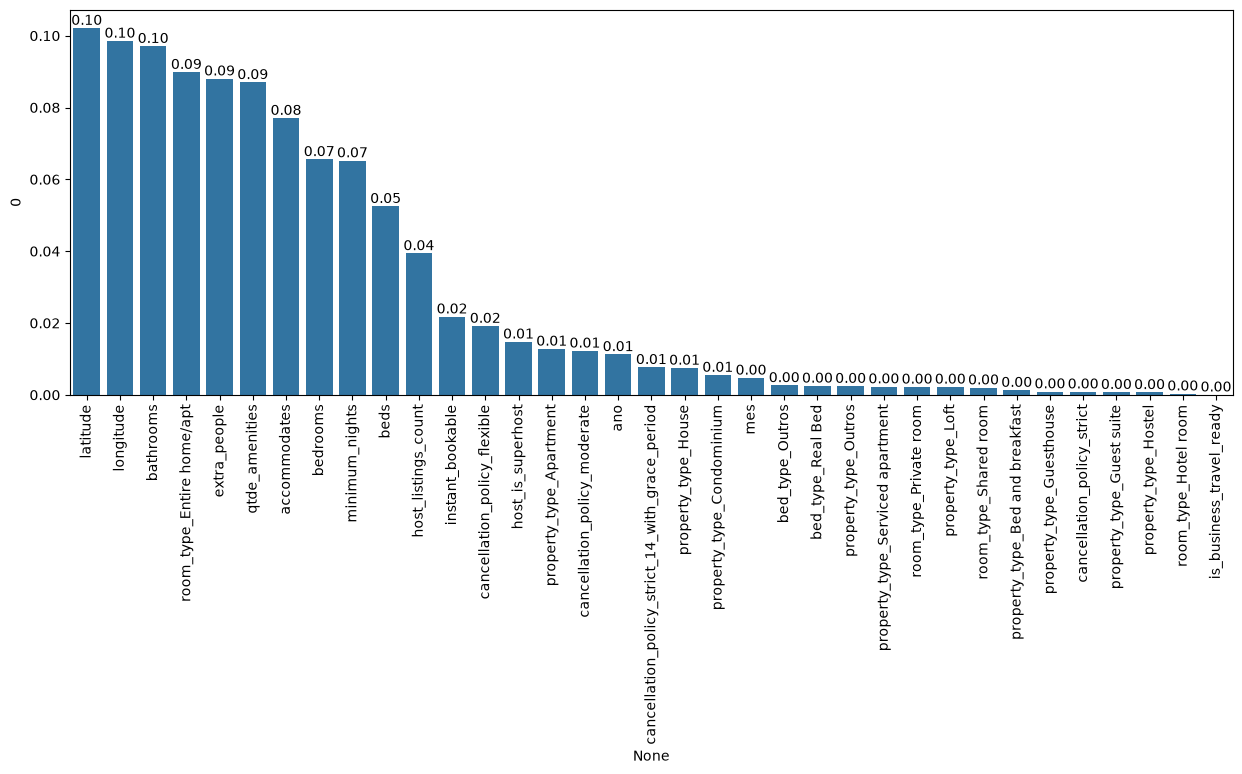

In [57]:
#mostrar as importâncias das features do modelo ExtraTreesRegressor
#print(modelo_et.feature_importances_)
#print(x_train.columns)

df_importancias_features = pd.DataFrame(modelo_et.feature_importances_, x_train.columns)
df_importancias_features = df_importancias_features.sort_values(by=0, ascending=False)
display(df_importancias_features)
plt.figure(figsize=(15, 5))
ax = sns.barplot(x= df_importancias_features.index, y= df_importancias_features[0])
ax.tick_params(axis='x', rotation=90)
#colocar os valores das importâncias acima das barras com duas casas decimais
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

# Ajuste final do modelo 

- Verificado que algumas features não são tão importantes para o modelo, então vamos excluir as features de baixa importância e treinar o modelo ExtraTreesRegressor novamente.
- Resultado das métricas do modelo vencedor 

Métricas do modelo ExtraTrees: 
- R²: 97.45% 
- RMSE: 42.62
- ExtraTrees: Tempo de execução do treino e teste: 734.04 segundos


- is_business_travel_ready não parece relevante para o modelo

In [58]:
#retirar a feature 'is_business_travel_ready'
base_airbnb_cod = base_airbnb_cod.drop(columns=['is_business_travel_ready'])
y = base_airbnb_cod['price']
x = base_airbnb_cod.drop(columns=['price'])
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=10)
#treinar o modelo ExtraTreesRegressor novamente com a feature retirada
nome_modelo = 'ExtraTrees'
tempo_inicio = time.time()
modelo_et.fit(x_train, y_train)
#testar o modelo
previsao = modelo_et.predict(x_test)
print(avaliar_modelo(nome_modelo, y_test, previsao)) 
tempo_fim = time.time()
tempo_execucao = tempo_fim - tempo_inicio
print(f'{nome_modelo}: Tempo de execução do treino e teste: {tempo_execucao:.2f} segundos')
print('-'*60)

Métricas do modelo ExtraTrees: 
R²: 97.47% 
RMSE: 42.43
ExtraTrees: Tempo de execução do treino e teste: 649.63 segundos
------------------------------------------------------------


In [59]:
#vamos testar o modelo retirando as duas colunas de bed_type
base_teste = base_airbnb_cod.copy()

#print(base_teste.shape)
for coluna in base_teste:
    if 'bed_type' in coluna:
        base_teste = base_teste.drop(columns=[coluna])
#print(base_teste.columns)        
#print(base_teste.shape)

y = base_teste['price']
x = base_teste.drop(columns=['price'])
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=10)
#treinar o modelo ExtraTreesRegressor novamente com a feature retirada
nome_modelo = 'ExtraTrees'
tempo_inicio = time.time()
modelo_et.fit(x_train, y_train)
#testar o modelo
previsao = modelo_et.predict(x_test)
print(avaliar_modelo(nome_modelo, y_test, previsao)) 
tempo_fim = time.time()
tempo_execucao = tempo_fim - tempo_inicio
print(f'{nome_modelo}: Tempo de execução do treino e teste: {tempo_execucao:.2f} segundos')
print('-'*60)

#verificado os dados após a retirada das duas features de bed_type,
# o modelo ficou com um desempenho bem parecido, então vamos deixar sem elas no modelo, 
#pois não foram importantes para o modelo, mesmo que o desempenho não tenha melhorado muito.

Métricas do modelo ExtraTrees: 
R²: 97.49% 
RMSE: 42.32
ExtraTrees: Tempo de execução do treino e teste: 507.96 segundos
------------------------------------------------------------


In [60]:
print(base_teste.columns) 

Index(['host_is_superhost', 'host_listings_count', 'latitude', 'longitude',
       'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price',
       'extra_people', 'minimum_nights', 'instant_bookable', 'ano', 'mes',
       'qtde_amenities', 'property_type_Apartment',
       'property_type_Bed and breakfast', 'property_type_Condominium',
       'property_type_Guest suite', 'property_type_Guesthouse',
       'property_type_Hostel', 'property_type_House', 'property_type_Loft',
       'property_type_Outros', 'property_type_Serviced apartment',
       'room_type_Entire home/apt', 'room_type_Hotel room',
       'room_type_Private room', 'room_type_Shared room',
       'cancellation_policy_flexible', 'cancellation_policy_moderate',
       'cancellation_policy_strict',
       'cancellation_policy_strict_14_with_grace_period'],
      dtype='str')


# Deploy do Projeto

- Passo 1 -> Criar arquivo do Modelo (joblib)<br>
- Passo 2 -> Escolher a forma de deploy:
    - Arquivo Executável + Tkinter
    - Deploy em Microsite (Flask)
    - Deploy apenas para uso direto Streamlit
- Passo 3 -> Outro arquivo Python (pode ser Jupyter ou PyCharm)
- Passo 4 -> Importar streamlit e criar código
- Passo 5 -> Atribuir ao botão o carregamento do modelo
- Passo 6 -> Deploy feito

In [61]:
x['price'] = y
x.to_csv('dados.csv')

In [62]:
import joblib
joblib.dump(modelo_et, 'modelo.joblib')


['modelo.joblib']